# Retinopatía diabética con fotos de fondo de ojo (APTOS 2019)

**IA II – Prof. Luis Carlos Guayacán**
Camilo Andrés Herrera Celis (2231530) · Camilo Andrés Bracho Rueda (2231517)

Clasificamos fondos de ojo en 5 niveles de retinopatía y comparamos:
- **CNNs desde cero:** CNN simple, AlexNet, SqueezeNet
- **CNNs preentrenadas:** DenseNet121, EfficientNetB0, MobileNetV2
- **Transformers:** ViT desde cero, híbrido DenseNet + Transformer, DeiT-Small y Swin-Tiny preentrenados
- **Flujo de dos etapas:** una etapa 1 decide "sano vs enfermo" y un segundo modelo clasifica la severidad (1 a 4). Probamos dos etapas 1: un autoencoder entrenado solo con ojos sanos y un clasificador binario (EfficientNetB0)
- **Regresión con umbrales optimizados:** la severidad como un número de 0 a 4, con cortes entre clases elegidos en validación

Después miramos con varios mapas de calor en qué se fija cada modelo. Todo en TensorFlow/Keras.

> Antes de empezar: `Entorno de ejecución → Cambiar tipo de entorno → T4 GPU`

## 1. Revisar la GPU

In [1]:
!nvidia-smi
# Swin-Tiny llegó a keras-hub en la versión 0.30 y necesita keras >= 3.15
!pip install -q kaggle
!pip install -q -U "keras>=3.15" "keras-hub>=0.30"
!pip show keras keras-hub tensorflow | grep -E "^(Name|Version)"

Sun Nov 15 00:44:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Imports y configuración

In [2]:
import os, random, time, json, shutil
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
import tensorflow as tf
import keras
from keras import layers, ops
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score, confusion_matrix

tf.get_logger().setLevel("ERROR")
import warnings  # avisos inofensivos de Swin (máscara) y MobileNetV2 (forma de entrada)
warnings.filterwarnings("ignore", message=".*does not support masking.*")
warnings.filterwarnings("ignore", message=".*is undefined or non-square.*")

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
if gpus:
    keras.mixed_precision.set_global_policy("mixed_float16")
print("TF", tf.__version__, "| Keras", keras.__version__, "| GPU:", gpus or "sin GPU :(")

CFG = dict(img=224, bs=32, seed=42, ben=True)
CLASES = ["0 Sin DR", "1 Leve", "2 Moderada", "3 Severa", "4 Proliferativa"]
DATA = "/content/aptos"
OUT = "/content/drive/MyDrive/IA2_DR"
AUTO = tf.data.AUTOTUNE
SOLO_CARGAR = True

keras.utils.set_random_seed(CFG["seed"])

TF 2.21.0 | Keras 3.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Guardar en Drive (recomendado)

Si se monta Drive antes de entrenar, los pesos y las historias quedan guardados ahí y no se pierden si se cae la sesión.

In [3]:
import os
from google.colab import drive

# Evita el error de 'Mountpoint must not already contain files' verificando si ya está montado
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive", force_remount=True)
else:
    print("Google Drive ya está montado.")

OUT = "/content/drive/MyDrive/IA2_DR"
os.makedirs(OUT, exist_ok=True)
print("OUT configurado en Drive:", OUT)

Mounted at /content/drive
OUT configurado en Drive: /content/drive/MyDrive/IA2_DR


## 4. Descargar APTOS 2019

Subir el `kaggle.json` cuando lo pida. Solo descomprimimos train porque el test de Kaggle no trae etiquetas.

In [4]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c aptos2019-blindness-detection -p /content
!unzip -q -o /content/aptos2019-blindness-detection.zip "train.csv" "train_images/*" -d /content/aptos
!rm /content/aptos2019-blindness-detection.zip

Saving kaggle.json to kaggle.json
100% 9.51G/9.51G [08:06<00:00, 21.0MB/s]



## 5. EDA rápido

3662 imágenes


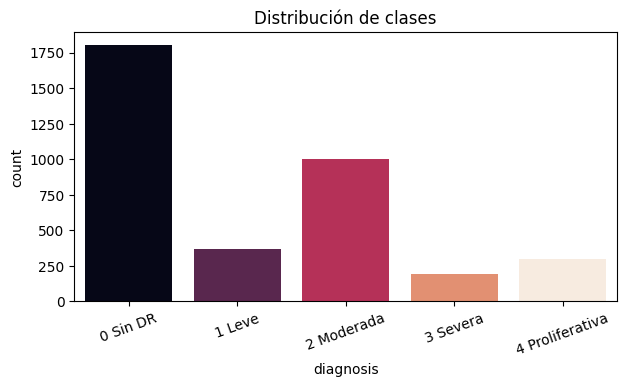

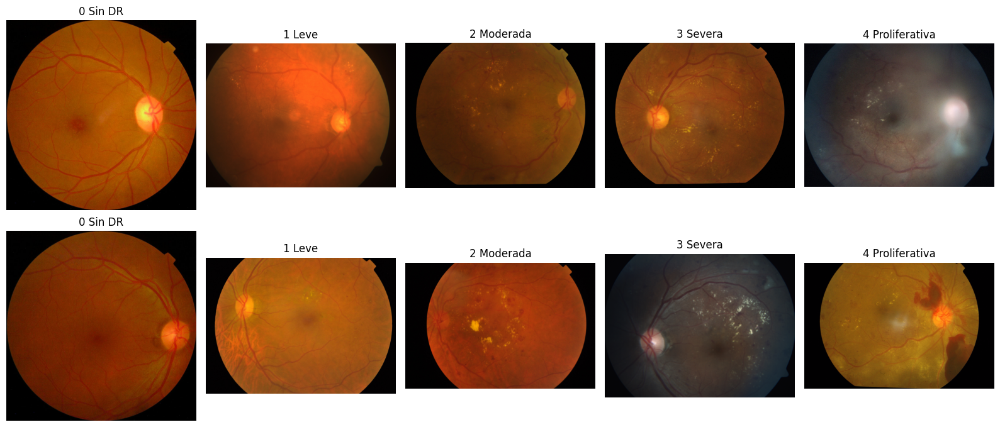

In [5]:
df = pd.read_csv(f"{DATA}/train.csv")
print(len(df), "imágenes")

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.countplot(x=df.diagnosis, ax=ax, palette="rocket", hue=df.diagnosis, legend=False)
ax.set_xticks(range(5), CLASES, rotation=20)
ax.set_title("Distribución de clases")
plt.show()

fig, ax = plt.subplots(2, 5, figsize=(16, 7))
for c in range(5):
    for r, iid in enumerate(df[df.diagnosis == c].sample(2, random_state=c).id_code):
        img = cv2.cvtColor(cv2.imread(f"{DATA}/train_images/{iid}.png"), cv2.COLOR_BGR2RGB)
        ax[r, c].imshow(img); ax[r, c].axis("off"); ax[r, c].set_title(CLASES[c])
plt.tight_layout(); plt.show()

## 6. Preprocesamiento (se hace una sola vez y queda en caché)

No se encontró caché. Procesando imágenes por primera vez (esto tardará unos minutos)...


  0%|          | 0/3662 [00:00<?, ?it/s]

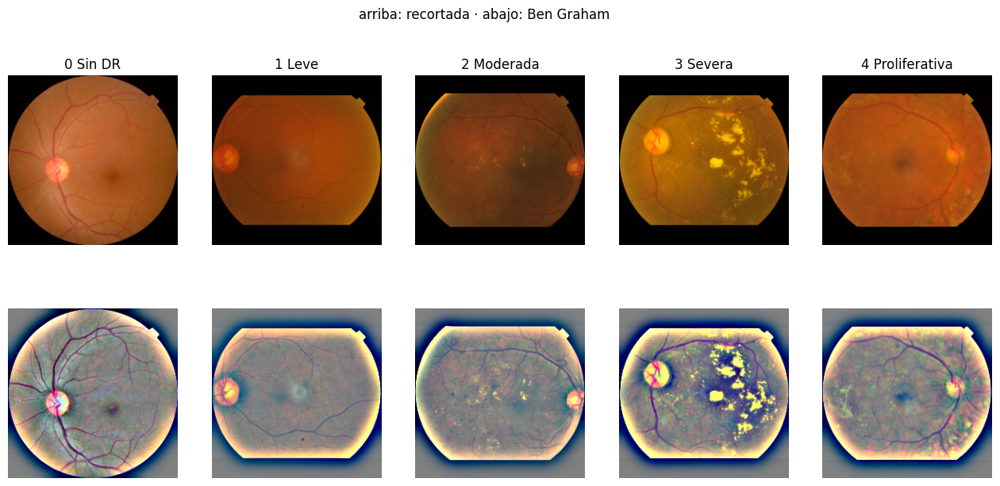

In [6]:
def recortar(img, tol=7):
    m = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) > tol
    if not m.any(): return img
    ys, xs = np.where(m)
    return img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def cargar(path, size):
    img = recortar(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
    h, w = img.shape[:2]; s = max(h, w)
    sq = np.zeros((s, s, 3), np.uint8)
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = img
    return cv2.resize(sq, (size, size), interpolation=cv2.INTER_AREA)

def ben_graham(img, sigma=10):
    return cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigma), -4, 128)

# Buscamos de manera flexible tanto '2231517.npy' como '2231517224.npy'
opcion_1 = "/content/2231517.npy"
opcion_2 = f"/content/2231517{CFG['img']}.npy"

if os.path.exists(opcion_1):
    cache = opcion_1
    print(f"Caché encontrado en {cache}. Cargando...")
    X = np.load(cache)
elif os.path.exists(opcion_2):
    cache = opcion_2
    print(f"Caché encontrado en {cache}. Cargando...")
    X = np.load(cache)
else:
    cache = opcion_2
    print("No se encontró caché. Procesando imágenes por primera vez (esto tardará unos minutos)...")
    X = np.stack([cargar(f"{DATA}/train_images/{i}.png", CFG["img"]) for i in tqdm(df.id_code)])
    np.save(cache, X)

Xb = np.stack([ben_graham(x) for x in X]) if CFG["ben"] else X
y = df.diagnosis.values

fig, ax = plt.subplots(2, 5, figsize=(16, 7))
for c in range(5):
    j = np.where(y == c)[0][0]
    ax[0, c].imshow(X[j]); ax[1, c].imshow(Xb[j])
    ax[0, c].set_title(CLASES[c]); ax[0, c].axis("off"); ax[1, c].axis("off")
plt.suptitle("arriba: recortada · abajo: Ben Graham"); plt.show()

In [7]:
import shutil

# Definimos las rutas en el almacenamiento local y en Google Drive
nombre_archivo = os.path.basename(cache)
ruta_drive = f"{OUT}/{nombre_archivo}"

try:
    # Si acabamos de procesar las imágenes y se guardaron localmente, las respaldamos en Drive
    if os.path.exists(cache) and not os.path.exists(ruta_drive):
        print(f"Guardando una copia de seguridad del preprocesamiento en Drive: {ruta_drive}...")
        shutil.copy(cache, ruta_drive)
        print("¡Copia de seguridad completada con éxito!")
    elif os.path.exists(ruta_drive):
        print(f"El archivo de preprocesamiento ya se encuentra respaldado de forma segura en tu Drive: {ruta_drive}")
    else:
        print("No se encontró archivo local para respaldar. Asegúrate de ejecutar la celda de preprocesamiento primero.")
except Exception as e:
    print(f"No se pudo guardar en Drive de forma automática: {e}")

El archivo de preprocesamiento ya se encuentra respaldado de forma segura en tu Drive: /content/drive/MyDrive/IA2_DR/2231517224.npy


## 7. Split y pipeline con `tf.data`

2563 549 550
pesos por clase: {0: 0.5, 1: 1.1, 2: 0.67, 3: 1.52, 4: 1.23}


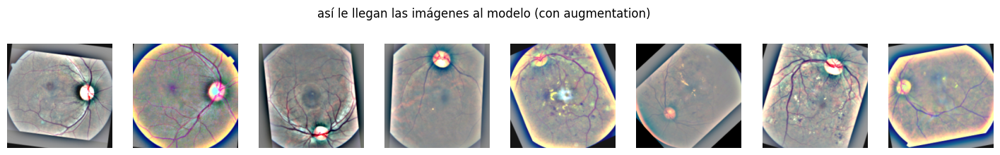

In [8]:
idx = np.arange(len(y))
tr, tmp = train_test_split(idx, test_size=0.3, stratify=y, random_state=CFG["seed"])
va, te = train_test_split(tmp, test_size=0.5, stratify=y[tmp], random_state=CFG["seed"])
print(len(tr), len(va), len(te))

MEAN = np.array([0.485, 0.456, 0.406], np.float32) * 255
STD = np.array([0.229, 0.224, 0.225], np.float32) * 255

def normalizar(x):
    return (tf.cast(x, tf.float32) - MEAN) / STD

aug = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5, fill_mode="constant"),
    layers.RandomZoom((-0.15, 0.0), fill_mode="constant"),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.15),
])

def hacer_ds(ids, entrenar=False, drop_remainder=None):
    if drop_remainder is None:
        drop_remainder = entrenar
    ds = tf.data.Dataset.from_tensor_slices((Xb[ids], keras.utils.to_categorical(y[ids], 5)))
    if entrenar:
        ds = ds.shuffle(len(ids), seed=CFG["seed"])
        ds = ds.batch(CFG["bs"], drop_remainder=drop_remainder)
        ds = ds.map(lambda a, b: (aug(tf.cast(a, tf.float32), training=True), b), num_parallel_calls=AUTO)
    else:
        ds = ds.batch(CFG["bs"])
    return ds.map(lambda a, b: (normalizar(a), b), num_parallel_calls=AUTO).prefetch(AUTO)

ds_train, ds_val, ds_test = hacer_ds(tr, True), hacer_ds(va), hacer_ds(te)

frec = np.bincount(y[tr], minlength=5)
w = (frec.sum() / frec) ** 0.5
CLASS_W = {i: float(v) for i, v in enumerate(w / w.mean())}
print("pesos por clase:", {k: round(v, 2) for k, v in CLASS_W.items()})

xb, _ = next(iter(hacer_ds(tr[:8], True, drop_remainder=False)))
fig, ax = plt.subplots(1, 8, figsize=(18, 2.6))
for a, im in zip(ax, xb.numpy()):
    a.imshow(np.clip(im * STD + MEAN, 0, 255).astype(np.uint8)); a.axis("off")
plt.suptitle("así le llegan las imágenes al modelo (con augmentation)"); plt.show()

## 8. Bloques compartidos

Piezas que usan varias redes: `conv_bn` y `cabeza` (CNNs) y el encoder del transformer (ViT e híbrido). Si se cambia algo aquí, afecta a todos los modelos que lo usan.

In [9]:
def conv_bn(x, f, k, s=1, nombre=None):
    x = layers.Conv2D(f, k, strides=s, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu", name=nombre)(x)

def cabeza(x, n=5, drop=0.3):
    x = layers.Dropout(drop)(x)
    return layers.Dense(n, dtype="float32", name="logits")(x)

class PosEmb(layers.Layer):
    def build(self, shape):
        self.pos = self.add_weight(shape=(1, shape[1], shape[2]), initializer=keras.initializers.TruncatedNormal(stddev=0.02), name="pos")

    def call(self, x):
        return x + ops.cast(self.pos, x.dtype)

def bloque_transformer(x, dim, heads, mlp, drop, nombre):
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h, att = layers.MultiHeadAttention(heads, dim // heads, dropout=drop, name=nombre)(h, h, return_attention_scores=True)
    x = layers.Add()([x, layers.Dropout(drop)(h)])
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.Dense(mlp, activation="gelu")(h)
    h = layers.Dropout(drop)(h)
    h = layers.Dense(dim)(h)
    return layers.Add()([x, layers.Dropout(drop)(h)]), att

def encoder(tokens, lado, dim, prof, heads, mlp, drop, n):
    x = PosEmb()(tokens)
    atts = []
    for i in range(prof):
        x, a = bloque_transformer(x, dim, heads, mlp, drop, f"att{i}")
        atts.append(a)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.Reshape((lado, lado, dim), name="mapa_tokens")(x)
    x = layers.GlobalAveragePooling2D()(x)
    return cabeza(x, n, 0.1), atts

## 9. Función de entrenamiento

El callback calcula el QWK en validación al final de cada época y guarda los pesos solo cuando mejora. `entrenar()` también guarda la historia y el tiempo, así que si se cae la sesión se puede poner `SOLO_CARGAR = True` (en la celda 2) y correr las celdas de los modelos: cargan los pesos guardados en vez de reentrenar.

Cada red tiene su propia celda abajo con su arquitectura y sus hiperparámetros. Se pueden correr, cambiar y volver a correr una por una; el resultado reemplaza al anterior en `modelos`.

In [10]:
class QWK(keras.callbacks.Callback):
    def __init__(self, ds, y_true, ruta):
        super().__init__()
        self.ds, self.y_true, self.ruta, self.mejor, self.hist = ds, y_true, ruta, -np.inf, []

    def on_epoch_end(self, ep, logs=None):
        p = self.model.predict(self.ds, verbose=0).argmax(1)
        q = np.nan_to_num(cohen_kappa_score(self.y_true, p, weights="quadratic"))
        self.hist.append(q)
        if q > self.mejor:
            self.mejor = q
            self.model.save_weights(self.ruta)
        print(f"   val_qwk {q:.3f} (mejor {self.mejor:.3f})")

if "modelos" not in globals():
    modelos, capas, historias, tiempos = {}, {}, {}, {}

def entrenar(nombre, constructor, lr, epochs, wd=1e-4, ds_tr=None, ds_va=None, y_va=None, cw=None, registrar=True):
    import gc
    ds_tr = ds_train if ds_tr is None else ds_tr
    ds_va = ds_val if ds_va is None else ds_va
    y_va = y[va] if y_va is None else y_va
    cw = CLASS_W if cw is None else cw
    keras.utils.set_random_seed(CFG["seed"])
    model, capa = constructor()
    print(f"{nombre}: {model.count_params() / 1e6:.2f} M params | capa CAM: {capa} {model.get_layer(capa).output.shape}")
    ruta, ruta_t = f"{OUT}/{nombre}.weights.h5", f"{OUT}/tiempos.json"
    t_guardados = json.load(open(ruta_t)) if os.path.exists(ruta_t) else {}
    if SOLO_CARGAR and os.path.exists(ruta):
        model.load_weights(ruta)
        hist = pd.read_csv(f"{OUT}/hist_{nombre}.csv")
        t = t_guardados.get(nombre, np.nan)
        print("pesos cargados desde", ruta)
    else:
        pasos = epochs * len(ds_tr)
        sched = keras.optimizers.schedules.CosineDecay(lr / 100, pasos, warmup_target=lr, warmup_steps=int(0.1 * pasos))
        opt = keras.optimizers.AdamW(sched, weight_decay=wd, global_clipnorm=1.0)
        model.compile(opt, keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=0.05), metrics=["accuracy"])
        cb = QWK(ds_va, y_va, ruta)
        t0 = time.time()
        h = model.fit(ds_tr, validation_data=ds_va, epochs=epochs, class_weight=cw, callbacks=[cb], shuffle=False, verbose=2)
        t = time.time() - t0
        model.load_weights(ruta)
        hist = pd.DataFrame(h.history).assign(val_qwk=cb.hist, ep=np.arange(1, epochs + 1))
        hist.to_csv(f"{OUT}/hist_{nombre}.csv", index=False)
        t_guardados[nombre] = t
        json.dump(t_guardados, open(ruta_t, "w"))
    if registrar:
        modelos[nombre], capas[nombre], historias[nombre], tiempos[nombre] = model, capa, hist, t
    print(f"--> {nombre} listo en {t / 60:.1f} min" if not pd.isna(t) else f"--> {nombre} listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)")

    # Liberar memoria de GPU y RAM después de entrenar/cargar el modelo
    gc.collect()
    keras.backend.clear_session()

    return model, capa, hist, t

## 10. CNN simple (desde cero)

4 bloques de 2 convoluciones + BatchNorm + ReLU. Es el baseline.

In [11]:
def cnn_simple(n=5):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = inp
    for i, f in enumerate([32, 64, 128, 256], 1):
        x = conv_bn(x, f, 3)
        x = conv_bn(x, f, 3, nombre=f"b{i}_relu2")
        if i < 4: x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    return keras.Model(inp, cabeza(x, n), name="cnn"), "b4_relu2"

entrenar("cnn", cnn_simple, lr=1e-3, epochs=15);

cnn: 1.18 M params | capa CAM: b4_relu2 (None, 28, 28, 256)
pesos cargados desde /content/drive/MyDrive/IA2_DR/cnn.weights.h5
--> cnn listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


In [12]:
# (Opcional) liberar memoria entre modelos. entrenar() ya hace esto al final, así que solo hace falta
# si Colab se queda sin RAM después de correr varias celdas seguidas.
import gc
gc.collect()
keras.backend.clear_session()
print("memoria liberada")

memoria liberada


## 11. AlexNet (desde cero, con BatchNorm)

5 convoluciones + 3 densas, como el original, pero con BatchNorm para que entrene desde cero con pocos datos.

In [13]:
def alexnet(n=5):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = conv_bn(inp, 96, 11, 4)
    x = layers.MaxPooling2D(3, 2)(x)
    x = conv_bn(x, 256, 5)
    x = layers.MaxPooling2D(3, 2, padding="same")(x)
    x = conv_bn(x, 384, 3)
    x = conv_bn(x, 384, 3)
    x = conv_bn(x, 256, 3, nombre="conv5_relu")
    x = layers.MaxPooling2D(3, 2)(x)
    x = layers.Flatten()(x)
    for _ in range(2):
        x = layers.Dense(4096, activation="relu")(x)
        x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(n, dtype="float32", name="logits")(x), name="alexnet"), "conv5_relu"

entrenar("alexnet", alexnet, lr=3e-4, epochs=15);

alexnet: 58.31 M params | capa CAM: conv5_relu (None, 14, 14, 256)
pesos cargados desde /content/drive/MyDrive/IA2_DR/alexnet.weights.h5
--> alexnet listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 12. SqueezeNet 1.1 (desde cero, con BatchNorm)

Fire modules: un "squeeze" de 1×1 que reduce canales y un "expand" con 1×1 y 3×3 en paralelo. Al final, conv 1×1 + pooling en vez de capas densas.

In [14]:
def fire(x, s, e, nombre):
    x = layers.Conv2D(s, 1, activation="relu")(x)
    a = layers.Conv2D(e, 1, activation="relu")(x)
    b = layers.Conv2D(e, 3, padding="same", activation="relu")(x)
    x = layers.Concatenate()([a, b])
    return layers.BatchNormalization(name=nombre)(x)

def squeezenet(n=5):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = conv_bn(inp, 64, 3, 2)
    x = layers.MaxPooling2D(3, 2)(x)
    x = fire(x, 16, 64, "fire2"); x = fire(x, 16, 64, "fire3")
    x = layers.MaxPooling2D(3, 2)(x)
    x = fire(x, 32, 128, "fire4"); x = fire(x, 32, 128, "fire5")
    x = layers.MaxPooling2D(3, 2)(x)
    for i, (s, e) in enumerate([(48, 192), (48, 192), (64, 256), (64, 256)], 6):
        x = fire(x, s, e, f"fire{i}")
    x = layers.Dropout(0.5)(x)
    x = layers.Conv2D(n, 1)(x)
    x = layers.GlobalAveragePooling2D(dtype="float32", name="logits")(x)
    return keras.Model(inp, x, name="squeezenet"), "fire9"

entrenar("squeezenet", squeezenet, lr=1e-3, epochs=15);

squeezenet: 0.74 M params | capa CAM: fire9 (None, 13, 13, 512)
pesos cargados desde /content/drive/MyDrive/IA2_DR/squeezenet.weights.h5
--> squeezenet listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 13. DenseNet121 (preentrenada en ImageNet)

Bloques densos de `keras.applications` con pesos de ImageNet; solo cambiamos la cabeza.

In [15]:
def densenet(n=5, pesos="imagenet"):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    base = keras.applications.DenseNet121(include_top=False, weights=pesos, input_tensor=inp)
    x = layers.GlobalAveragePooling2D()(base.output)
    return keras.Model(inp, cabeza(x, n), name="densenet"), "relu"

entrenar("densenet", densenet, lr=1e-4, epochs=15);

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
densenet: 7.04 M params | capa CAM: relu (None, 7, 7, 1024)
pesos cargados desde /content/drive/MyDrive/IA2_DR/densenet.weights.h5
--> densenet listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 14. ViT (desde cero)

Corta la imagen en parches de 16×16 (196 tokens), les suma una posición aprendida y los pasa por 6 bloques de atención. Usa más weight decay y más épocas porque arranca de cero.

In [16]:
def vit(n=5, patch=16, dim=192, prof=6, heads=3, mlp=384, drop=0.1):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    lado = CFG["img"] // patch
    x = layers.Conv2D(dim, patch, strides=patch, name="parches")(inp)
    x = layers.Reshape((lado * lado, dim))(x)
    out, atts = encoder(x, lado, dim, prof, heads, mlp, drop, n)
    m = keras.Model(inp, out, name="vit")
    m.atencion = keras.Model(inp, atts)
    return m, "mapa_tokens"

entrenar("vit", vit, lr=3e-4, epochs=30, wd=0.05);

vit: 1.97 M params | capa CAM: mapa_tokens (None, 14, 14, 192)
pesos cargados desde /content/drive/MyDrive/IA2_DR/vit.weights.h5
--> vit listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 15. Híbrido DenseNet + Transformer

Los tokens salen del mapa de 14×14 de una DenseNet preentrenada (no de los pixeles), y encima van 2 bloques de transformer.

In [17]:
def hibrido(n=5, dim=256, prof=2, heads=4, mlp=512, drop=0.1, pesos="imagenet"):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    base = keras.applications.DenseNet121(include_top=False, weights=pesos, input_tensor=inp)
    f = base.get_layer("conv4_block24_concat").output
    lado = f.shape[1]
    x = layers.Conv2D(dim, 1)(f)
    x = layers.Reshape((lado * lado, dim))(x)
    out, atts = encoder(x, lado, dim, prof, heads, mlp, drop, n)
    m = keras.Model(inp, out, name="hibrido")
    m.atencion = keras.Model(inp, atts)
    return m, "mapa_tokens"

entrenar("hibrido", hibrido, lr=1e-4, epochs=15);

hibrido: 5.69 M params | capa CAM: mapa_tokens (None, 14, 14, 256)
pesos cargados desde /content/drive/MyDrive/IA2_DR/hibrido.weights.h5
--> hibrido listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 16. EfficientNetB0 (preentrenada en ImageNet)

Escala ancho, profundidad y resolución de forma balanceada, y logra más precisión con menos parámetros que DenseNet. Trae su propia normalización adentro (espera pixeles de 0 a 255), así que primero deshacemos la nuestra con `Normalization(invert=True)`.

In [18]:
def efficientnet(n=5, pesos="imagenet"):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = layers.Normalization(mean=MEAN, variance=STD ** 2, invert=True)(inp)
    base = keras.applications.EfficientNetB0(include_top=False, weights=pesos, input_tensor=x)
    x = layers.GlobalAveragePooling2D()(base.output)
    return keras.Model(inp, cabeza(x, n), name="efficientnet"), "top_activation"

entrenar("efficientnet", efficientnet, lr=2e-4, epochs=15);

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
efficientnet: 4.06 M params | capa CAM: top_activation (None, 7, 7, 1280)
pesos cargados desde /content/drive/MyDrive/IA2_DR/efficientnet.weights.h5
--> efficientnet listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 17. MobileNetV2 (preentrenada en ImageNet)

Pensada para celulares: convoluciones separables y bloques "invertidos" con atajos. Es la más liviana de las preentrenadas, así que es la candidata para Edge AI. Espera pixeles entre -1 y 1.

In [19]:
def mobilenet(n=5, pesos="imagenet"):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = layers.Normalization(mean=MEAN, variance=STD ** 2, invert=True)(inp)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    base = keras.applications.MobileNetV2(include_top=False, weights=pesos, input_tensor=x)
    x = layers.GlobalAveragePooling2D()(base.output)
    return keras.Model(inp, cabeza(x, n), name="mobilenet"), "out_relu"

entrenar("mobilenet", mobilenet, lr=2e-4, epochs=15);

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
mobilenet: 2.26 M params | capa CAM: out_relu (None, 7, 7, 1280)
pesos cargados desde /content/drive/MyDrive/IA2_DR/mobilenet.weights.h5
--> mobilenet listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 18. DeiT-Small (transformer preentrenado, KerasHub)

DeiT es un ViT entrenado de forma "eficiente en datos": usa distillation de una CNN y mucha augmentation, por eso funciona con menos datos que el ViT original. Usamos los pesos de ImageNet de KerasHub (se descargan de Kaggle, por eso hace falta el `kaggle.json`).

La salida trae 198 tokens: 196 parches + el token CLS + el de distillation. Quitamos los 2 primeros y armamos el mapa de 14×14 para poder sacar Grad-CAM igual que en el ViT.

In [20]:
import keras_hub

def deit(n=5):
    bb = keras_hub.models.DeiTBackbone.from_preset("deit_small_distilled_patch16_224_imagenet",
                                                   dtype=keras.mixed_precision.global_policy().name)
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = layers.Cropping1D((2, 0))(bb(inp))
    lado = CFG["img"] // 16
    x = layers.Reshape((lado, lado, x.shape[-1]), name="mapa_tokens")(x)
    x = layers.GlobalAveragePooling2D()(x)
    return keras.Model(inp, cabeza(x, n, 0.1), name="deit"), "mapa_tokens"

entrenar("deit", deit, lr=1e-4, epochs=15, wd=0.05);

100%|██████████| 616/616 [00:00<00:00, 1.27MB/s]


deit: 21.67 M params | capa CAM: mapa_tokens (None, 14, 14, 384)
pesos cargados desde /content/drive/MyDrive/IA2_DR/deit.weights.h5
--> deit listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)


## 19. Swin-Tiny (transformer jerárquico preentrenado, KerasHub)

Swin calcula la atención en ventanas locales de 7×7 que se van desplazando, y va reduciendo la resolución como una CNN. Es más eficiente que un ViT en imágenes grandes. La última etapa sale de 7×7, así que su Grad-CAM es más grueso.

Si da error con mixed precision, cambien `dtype=...` por `dtype="float32"`.

**Si sale el aviso de que no está Swin:** la celda de la sección 1 ya actualiza `keras-hub`, pero si la sesión se había abierto antes con la versión vieja hay que ir a `Entorno de ejecución → Reiniciar sesión` y correr de nuevo desde arriba (con `SOLO_CARGAR = True` los demás modelos cargan en segundos).

In [21]:
import keras_hub
print("keras-hub", keras_hub.__version__, "| trae Swin:", hasattr(keras_hub.models, "SwinTransformerBackbone"))

keras-hub 0.33.0 | trae Swin: True


In [22]:
import keras
import keras_hub

def swin(n=5):
    bb = keras_hub.models.SwinTransformerBackbone.from_preset("swin_tiny_patch4_window7_224",
                                                              dtype=keras.mixed_precision.global_policy().name)
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = bb(inp)
    lado = int(x.shape[1] ** 0.5)
    x = layers.Reshape((lado, lado, x.shape[-1]), name="mapa_tokens")(x)
    x = layers.GlobalAveragePooling2D()(x)
    return keras.Model(inp, cabeza(x, n, 0.1), name="swin"), "mapa_tokens"

if hasattr(keras_hub.models, "SwinTransformerBackbone"):
    entrenar("swin", swin, lr=1e-4, epochs=15, wd=0.05)
else:
    print(f"keras-hub {keras_hub.__version__} no trae Swin, se salta. Corran la celda de la sección 1, reinicien la sesión y vuelvan a correr")

swin: 27.52 M params | capa CAM: mapa_tokens (None, 7, 7, 768)
pesos cargados desde /content/drive/MyDrive/IA2_DR/swin.weights.h5
--> swin listo en 15.7 min


## 20. Flujo de dos etapas – Etapa 1: autoencoder (sano vs enfermo)

La idea: un autoencoder entrenado **solo con ojos sanos (clase 0)** aprende a reconstruir cómo se ve una retina normal. Cuando le llega un ojo con lesiones (hemorragias, exudados), no sabe reconstruirlas y el **error de reconstrucción** sube. Si el error pasa un umbral, el ojo se marca como enfermo y pasa a la etapa 2.

- Encoder: 4 convoluciones con stride 2 (224 → 14) y un cuello de botella de 14×14×32, que comprime la imagen unas 24 veces para que no pueda copiarla tal cual.
- Decoder: 4 `Conv2DTranspose` de vuelta a 224×224.
- Usamos las imágenes con Ben Graham porque resalta las lesiones.

**Primer intento:** con el error **promedio** de toda la retina, el autoencoder no separó sanos de enfermos (AUC 0.42 en val y 0.44 en test, peor que el azar). Las lesiones son puntos pequeños y el promedio lo dominan la iluminación y la textura general, que el autoencoder reconstruye bien en cualquier ojo.

**Segundo intento (esta celda):** el autoencoder es el mismo y no se reentrena; lo que cambia es **cómo se mide el error**.
- Se quita el anillo del borde de la retina (erosión de la máscara), porque Ben Graham crea ahí un halo que el autoencoder reconstruye mal en todos los ojos.
- Se comparan 4 formas de resumir el mapa de error: el **promedio**, el **percentil 99**, el **promedio del 1% de pixeles peores** y el **máximo del mapa suavizado**. Las tres últimas se fijan en las zonas peores, que es donde debería estar una lesión.
- Se elige automáticamente la que mejor separa en **validación** (mayor AUC), y el umbral con el índice de Youden. El test no se usa para elegir nada.

autoencoder: 0.52 M params | entrena con 1263 ojos sanos
pesos cargados desde /content/drive/MyDrive/IA2_DR/autoencoder.weights.h5


,AUC en val
promedio,0.374
percentil 99,0.452
top 1%,0.515
max suavizado,0.434


Medida elegida: top 1% | AUC val 0.515 | umbral 0.03999
Ojo: con AUC < 0.75 el autoencoder sigue siendo una puerta débil, la mayoría de errores del flujo vendrán de aquí


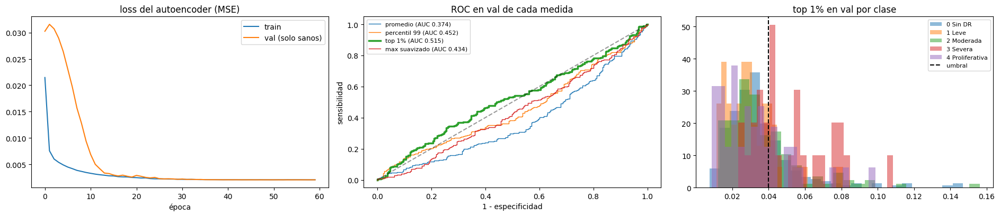

In [23]:
from sklearn.metrics import roc_curve, roc_auc_score

def autoencoder():
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    x = inp
    for f in [32, 64, 128, 128]:
        x = conv_bn(x, f, 3, 2)
    x = layers.Conv2D(32, 1, activation="relu", name="codigo")(x)
    for f in [128, 128, 64, 32]:
        x = layers.Conv2DTranspose(f, 3, strides=2, padding="same", use_bias=False)(x)
        x = layers.Activation("relu")(layers.BatchNormalization()(x))
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid", dtype="float32", name="reconstruccion")(x)
    return keras.Model(inp, out, name="autoencoder")

def ds_ae(ids, entrenar=False):
    ds = tf.data.Dataset.from_tensor_slices(Xb[ids])
    if entrenar:
        ds = ds.shuffle(len(ids), seed=CFG["seed"])
    ds = ds.batch(CFG["bs"]).map(lambda a: tf.cast(a, tf.float32) / 255.0, num_parallel_calls=AUTO)
    if entrenar:
        ds = ds.map(lambda a: tf.image.random_flip_up_down(tf.image.random_flip_left_right(a)), num_parallel_calls=AUTO)
    return ds.map(lambda a: (a, a)).prefetch(AUTO)

EROSION = 15

def mapas_error(ids, lote=64):
    mapas, mascaras = [], []
    k = np.ones((EROSION, EROSION), np.uint8)
    for s in range(0, len(ids), lote):
        b = ids[s:s + lote]
        x = Xb[b].astype(np.float32) / 255.0
        r = ae.predict(x, verbose=0)
        mascaras.append(np.stack([cv2.erode((X[j].max(-1) > 15).astype(np.uint8), k) for j in b]).astype(np.float32))
        mapas.append(((x - r) ** 2).mean(-1) * mascaras[-1])
    return np.concatenate(mapas), np.concatenate(mascaras)

def puntajes(mapas, mascaras):
    p = {"promedio": [], "percentil 99": [], "top 1%": [], "max suavizado": []}
    for e, m in zip(mapas, mascaras):
        v = e[m > 0]
        p["promedio"].append(v.mean())
        p["percentil 99"].append(np.percentile(v, 99))
        p["top 1%"].append(np.sort(v)[-max(1, len(v) // 100):].mean())
        p["max suavizado"].append(cv2.GaussianBlur(e, (0, 0), 4)[m > 0].max())
    return {k: np.array(v) for k, v in p.items()}

def error_reconstruccion(ids, por_pixel=False):
    mapas, mascaras = mapas_error(np.asarray(ids))
    return mapas if por_pixel else puntajes(mapas, mascaras)[MODO]

keras.utils.set_random_seed(CFG["seed"])
sanos_tr, sanos_va = tr[y[tr] == 0], va[y[va] == 0]
ae = autoencoder()
print(f"autoencoder: {ae.count_params() / 1e6:.2f} M params | entrena con {len(sanos_tr)} ojos sanos")
ruta_ae = f"{OUT}/autoencoder.weights.h5"
if SOLO_CARGAR and os.path.exists(ruta_ae):
    ae.load_weights(ruta_ae)
    hist_ae = pd.read_csv(f"{OUT}/hist_autoencoder.csv")
    print("pesos cargados desde", ruta_ae)
else:
    ae.compile(keras.optimizers.Adam(1e-3), "mse")
    cbs = [keras.callbacks.ModelCheckpoint(ruta_ae, save_best_only=True, save_weights_only=True),
           keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3)]
    t0 = time.time()
    h = ae.fit(ds_ae(sanos_tr, True), validation_data=ds_ae(sanos_va), epochs=60, callbacks=cbs, verbose=2)
    hist_ae = pd.DataFrame(h.history).assign(tiempo=time.time() - t0)
    hist_ae.to_csv(f"{OUT}/hist_autoencoder.csv", index=False)

mapas_va, masc_va = mapas_error(va)
p_va = puntajes(mapas_va, masc_va)
auc_va = {k: roc_auc_score(y[va] > 0, v) for k, v in p_va.items()}
MODO = max(auc_va, key=auc_va.get)
err_va = p_va[MODO]
fpr, tpr, thr = roc_curve(y[va] > 0, err_va)
UMBRAL = thr[np.argmax(tpr - fpr)]
display(pd.Series(auc_va, name="AUC en val").round(3).to_frame())
print(f"Medida elegida: {MODO} | AUC val {auc_va[MODO]:.3f} | umbral {UMBRAL:.5f}")
if auc_va[MODO] < 0.75:
    print("Ojo: con AUC < 0.75 el autoencoder sigue siendo una puerta débil, la mayoría de errores del flujo vendrán de aquí")

fig, ax = plt.subplots(1, 3, figsize=(19, 4.2))
ax[0].plot(hist_ae["loss"], label="train"); ax[0].plot(hist_ae["val_loss"], label="val (solo sanos)")
ax[0].set_title("loss del autoencoder (MSE)"); ax[0].set_xlabel("época"); ax[0].legend()
for k, v in p_va.items():
    f_, t_, _ = roc_curve(y[va] > 0, v)
    ax[1].plot(f_, t_, label=f"{k} (AUC {auc_va[k]:.3f})", lw=2.5 if k == MODO else 1)
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4); ax[1].legend(fontsize=8)
ax[1].set_title("ROC en val de cada medida"); ax[1].set_xlabel("1 - especificidad"); ax[1].set_ylabel("sensibilidad")
for c in range(5):
    ax[2].hist(err_va[y[va] == c], bins=25, alpha=0.5, label=CLASES[c], density=True)
ax[2].axvline(UMBRAL, color="k", ls="--", label="umbral")
ax[2].set_title(f"{MODO} en val por clase"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 21. Flujo de dos etapas – Etapa 2: clasificador de severidad (solo enfermos)

Este modelo solo ve ojos enfermos (clases 1 a 4) y aprende a separar los niveles, sin tener que aprender además qué es un ojo sano. Usamos DenseNet121 preentrenada porque fue de las mejores en la primera ronda. Para usar otra red, cambien `densenet` por `efficientnet`, `mobilenet`, etc.

Las etiquetas pasan de 1–4 a 0–3 quitando la columna de la clase 0 del one-hot.

In [24]:
# Definimos la arquitectura DenseNet para la etapa 2 en caso de que no esté cargada en la sesión actual
def densenet(n=5, pesos="imagenet"):
    inp = keras.Input((CFG["img"], CFG["img"], 3))
    base = keras.applications.DenseNet121(include_top=False, weights=pesos, input_tensor=inp)
    x = layers.GlobalAveragePooling2D()(base.output)
    return keras.Model(inp, cabeza(x, n), name="densenet"), "relu"

enf_tr, enf_va = tr[y[tr] > 0], va[y[va] > 0]
solo_sev = lambda a, b: (a, b[:, 1:])
ds_sev_tr = hacer_ds(enf_tr, True).map(solo_sev)
ds_sev_va = hacer_ds(enf_va).map(solo_sev)

frec_sev = np.bincount(y[enf_tr] - 1, minlength=4)
w_sev = (frec_sev.sum() / frec_sev) ** 0.5
CW_SEV = {i: float(v) for i, v in enumerate(w_sev / w_sev.mean())}
print(f"entrena con {len(enf_tr)} ojos enfermos | pesos por clase:", {k + 1: round(v, 2) for k, v in CW_SEV.items()})

m2, c2, h2, t2 = entrenar("severidad", lambda: densenet(n=4), lr=1e-4, epochs=15,
                          ds_tr=ds_sev_tr, ds_va=ds_sev_va, y_va=y[enf_va] - 1, cw=CW_SEV, registrar=False)
etapa2 = dict(modelo=m2, capa=c2, hist=h2, t=t2)

entrena con 1300 ojos enfermos | pesos por clase: {1: 0.97, 2: 0.59, 3: 1.35, 4: 1.09}
severidad: 7.04 M params | capa CAM: relu (None, 7, 7, 1024)
pesos cargados desde /content/drive/MyDrive/IA2_DR/severidad.weights.h5
--> severidad listo en 12.4 min


## 21b. Etapa 1 nueva: clasificador binario sano vs enfermo

El autoencoder no sirvió como filtro (AUC ≈ 0.55 en test), pero la etapa 2 sí funciona: con una etapa 1 perfecta el flujo llega a 0.89 de QWK. Así que cambiamos solo la puerta.

- Una **EfficientNetB0 preentrenada** que decide entre 2 clases: sano (0) o enfermo (1 a 4). A diferencia del autoencoder, ve ejemplos de las dos clases, así que aprende directamente qué separa un ojo enfermo de uno sano.
- Mismo protocolo que los demás modelos (`entrenar()`), con pesos por clase. Con 2 clases el "val_qwk" del callback es el kappa de Cohen normal.
- El **umbral** sobre la probabilidad de "enfermo" no se elige con Youden: se elige el que da **mayor QWK del flujo completo en validación**, porque eso es lo que nos importa al final. El test no se usa para elegir nada.

Hay que haber corrido antes la sección 21 (etapa 2). La sección 20 (autoencoder) solo hace falta para comparar las dos etapas 1 en la gráfica.

entrena con 2563 ojos (1263 sanos, 1300 enfermos) | pesos: {0: 1.01, 1: 0.99}
binario: 4.05 M params | capa CAM: top_activation (None, 7, 7, 1280)
pesos cargados desde /content/drive/MyDrive/IA2_DR/binario.weights.h5
--> binario listo en 13.1 min
Etapa 1 binaria en val: AUC 0.991 | umbral 0.32 | sensibilidad 0.960 | especificidad 0.993
QWK del flujo en val: 0.869 con umbral 0.32 (con 0.50 sería 0.864)


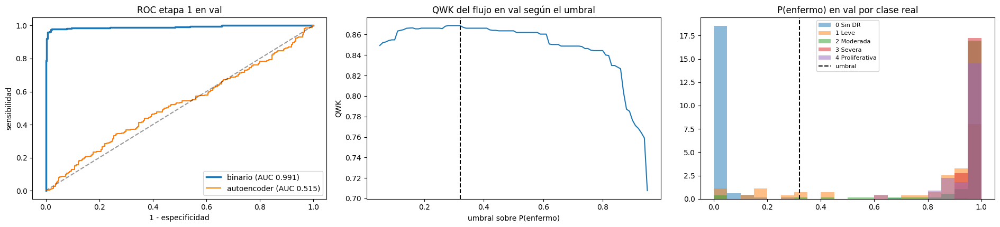

In [25]:
if "etapa2" not in globals():
    raise RuntimeError("Primero corran la sección 21 (etapa 2): el umbral se elige con el flujo completo")

if "efficientnet" not in globals():  # la misma de la sección 16, por si se saltaron esas celdas
    def efficientnet(n=5, pesos="imagenet"):
        inp = keras.Input((CFG["img"], CFG["img"], 3))
        x = layers.Normalization(mean=MEAN, variance=STD ** 2, invert=True)(inp)
        base = keras.applications.EfficientNetB0(include_top=False, weights=pesos, input_tensor=x)
        x = layers.GlobalAveragePooling2D()(base.output)
        return keras.Model(inp, cabeza(x, n), name="efficientnet"), "top_activation"

def softmax_np(z):
    z = np.asarray(z, np.float32)
    e = np.exp(z - z.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

y_bin = (y > 0).astype(int)
a_binario = lambda a, b: (a, tf.stack([b[:, 0], 1.0 - b[:, 0]], -1))  # one-hot [sano, enfermo]
ds_bin_tr = hacer_ds(tr, True).map(a_binario)
ds_bin_va = hacer_ds(va).map(a_binario)

frec_bin = np.bincount(y_bin[tr], minlength=2)
w_bin = (frec_bin.sum() / frec_bin) ** 0.5
CW_BIN = {i: float(v) for i, v in enumerate(w_bin / w_bin.mean())}
print(f"entrena con {len(tr)} ojos ({frec_bin[0]} sanos, {frec_bin[1]} enfermos) | pesos:", {k: round(v, 2) for k, v in CW_BIN.items()})

mb, cb_bin, hb, tb = entrenar("binario", lambda: efficientnet(n=2), lr=2e-4, epochs=15,
                              ds_tr=ds_bin_tr, ds_va=ds_bin_va, y_va=y_bin[va], cw=CW_BIN, registrar=False)
etapa1_bin = dict(modelo=mb, capa=cb_bin, hist=hb, t=tb)

def prob_enfermo(ids):
    return softmax_np(etapa1_bin["modelo"].predict(hacer_ds(ids), verbose=0))[:, 1]

def severidad(ids):
    return etapa2["modelo"].predict(hacer_ds(ids), verbose=0).argmax(1) + 1

p_bin_va = prob_enfermo(va)
sev_va = severidad(va)
auc_bin_va = roc_auc_score(y_bin[va], p_bin_va)

UMBRALES = np.round(np.linspace(0.05, 0.95, 91), 2)
qwk_umbral = np.array([cohen_kappa_score(y[va], np.where(p_bin_va > u, sev_va, 0), weights="quadratic") for u in UMBRALES])
cand = UMBRALES[np.isclose(qwk_umbral, qwk_umbral.max())]
UMBRAL_BIN = float(cand[np.abs(cand - 0.5).argmin()])  # si hay empate, el más cercano a 0.5
enf_va_pred = p_bin_va > UMBRAL_BIN
real_va = y_bin[va] == 1
print(f"Etapa 1 binaria en val: AUC {auc_bin_va:.3f} | umbral {UMBRAL_BIN:.2f} | "
      f"sensibilidad {(enf_va_pred & real_va).sum() / real_va.sum():.3f} | especificidad {(~enf_va_pred & ~real_va).sum() / (~real_va).sum():.3f}")
print(f"QWK del flujo en val: {qwk_umbral.max():.3f} con umbral {UMBRAL_BIN:.2f} (con 0.50 sería {qwk_umbral[UMBRALES == 0.5][0]:.3f})")

fig, ax = plt.subplots(1, 3, figsize=(19, 4.4))
f_, t_, _ = roc_curve(y_bin[va], p_bin_va)
ax[0].plot(f_, t_, lw=2.5, label=f"binario (AUC {auc_bin_va:.3f})")
if "err_va" in globals():
    f_, t_, _ = roc_curve(y_bin[va], err_va)
    ax[0].plot(f_, t_, label=f"autoencoder (AUC {roc_auc_score(y_bin[va], err_va):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4); ax[0].legend()
ax[0].set_title("ROC etapa 1 en val"); ax[0].set_xlabel("1 - especificidad"); ax[0].set_ylabel("sensibilidad")
ax[1].plot(UMBRALES, qwk_umbral); ax[1].axvline(UMBRAL_BIN, color="k", ls="--")
ax[1].set_title("QWK del flujo en val según el umbral"); ax[1].set_xlabel("umbral sobre P(enfermo)"); ax[1].set_ylabel("QWK")
for c in range(5):
    ax[2].hist(p_bin_va[y[va] == c], bins=20, range=(0, 1), alpha=0.5, label=CLASES[c], density=True)
ax[2].axvline(UMBRAL_BIN, color="k", ls="--", label="umbral"); ax[2].legend(fontsize=8)
ax[2].set_title("P(enfermo) en val por clase real")
plt.tight_layout(); plt.show()

## 21c. Regresión con umbrales optimizados

En vez de 5 salidas con softmax, el modelo predice **un solo número** de severidad (por ejemplo 2.3) y después se convierte a clase con 4 cortes. Así el modelo sabe desde el entrenamiento que equivocarse de 0 a 4 es peor que de 0 a 1, igual que el QWK.

- Red: **EfficientNetB0 preentrenada** con una salida lineal, para comparar directo con la EfficientNetB0 de 5 clases (sección 16).
- Pérdida **Huber** (SmoothL1), la misma que usó el ganador de APTOS 2019. Es como el error cuadrático cerca del valor real y como el absoluto lejos de él, así que es menos sensible a etiquetas ruidosas.
- Los pesos por clase entran como *sample weights*, porque `class_weight` de Keras solo sirve para clasificación.
- Durante el entrenamiento la mejor época se elige con los cortes fijos 0.5, 1.5, 2.5 y 3.5.
- Al final se **optimizan los 4 cortes en validación** para maximizar el QWK (búsqueda por coordenadas: se mueve un corte a la vez entre sus vecinos y se repite). Los cortes se ajustan con validación, así que el número que cuenta es el de test.

regresion: 4.05 M params | salida (None, 1)
pesos cargados desde /content/drive/MyDrive/IA2_DR/regresion.weights.h5
--> regresion listo en 11.4 min
cortes optimizados: [0.354 0.94  2.5   3.646]
QWK en val: cortes fijos 0.846 → cortes optimizados 0.875


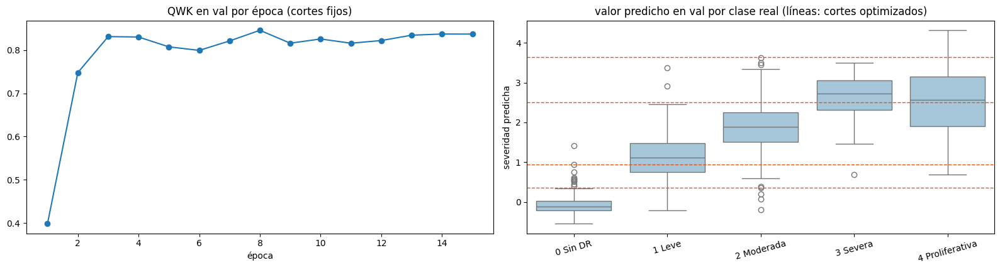

In [26]:
if "efficientnet" not in globals():
    raise RuntimeError("Primero corran la sección 16 o la 21b, que definen efficientnet()")

CORTES_BASE = np.array([0.5, 1.5, 2.5, 3.5])

def a_clase(pred, cortes=CORTES_BASE):
    return np.digitize(np.ravel(pred), cortes)

class QWKReg(keras.callbacks.Callback):
    def __init__(self, ds, y_true, ruta):
        super().__init__()
        self.ds, self.y_true, self.ruta, self.mejor, self.hist = ds, y_true, ruta, -np.inf, []

    def on_epoch_end(self, ep, logs=None):
        q = np.nan_to_num(cohen_kappa_score(self.y_true, a_clase(self.model.predict(self.ds, verbose=0)), weights="quadratic"))
        self.hist.append(q)
        if q > self.mejor:
            self.mejor = q
            self.model.save_weights(self.ruta)
        print(f"   val_qwk {q:.3f} (mejor {self.mejor:.3f})")

CW_VEC = tf.constant([CLASS_W[i] for i in range(5)], tf.float32)

def a_regresion(a, b, pesos=False):
    c = tf.argmax(b, -1)
    t = tf.cast(c, tf.float32)[:, None]
    return (a, t, tf.gather(CW_VEC, c)) if pesos else (a, t)

ds_reg_tr = hacer_ds(tr, True).map(lambda a, b: a_regresion(a, b, pesos=True))
ds_reg_va = hacer_ds(va).map(a_regresion)

def entrenar_regresion(nombre, constructor, lr, epochs, wd=1e-4):
    import gc
    keras.utils.set_random_seed(CFG["seed"])
    model, capa = constructor()
    print(f"{nombre}: {model.count_params() / 1e6:.2f} M params | salida {model.output.shape}")
    ruta, ruta_t = f"{OUT}/{nombre}.weights.h5", f"{OUT}/tiempos.json"
    t_guardados = json.load(open(ruta_t)) if os.path.exists(ruta_t) else {}
    if SOLO_CARGAR and os.path.exists(ruta):
        model.load_weights(ruta)
        hist = pd.read_csv(f"{OUT}/hist_{nombre}.csv")
        t = t_guardados.get(nombre, np.nan)
        print("pesos cargados desde", ruta)
    else:
        pasos = epochs * len(ds_reg_tr)
        sched = keras.optimizers.schedules.CosineDecay(lr / 100, pasos, warmup_target=lr, warmup_steps=int(0.1 * pasos))
        opt = keras.optimizers.AdamW(sched, weight_decay=wd, global_clipnorm=1.0)
        model.compile(opt, keras.losses.Huber(delta=1.0), metrics=["mae"])
        cb = QWKReg(ds_reg_va, y[va], ruta)
        t0 = time.time()
        h = model.fit(ds_reg_tr, validation_data=ds_reg_va, epochs=epochs, callbacks=[cb], verbose=2)
        t = time.time() - t0
        model.load_weights(ruta)
        hist = pd.DataFrame(h.history).assign(val_qwk=cb.hist, ep=np.arange(1, epochs + 1))
        hist.to_csv(f"{OUT}/hist_{nombre}.csv", index=False)
        t_guardados[nombre] = t
        json.dump(t_guardados, open(ruta_t, "w"))
    print(f"--> {nombre} listo en {t / 60:.1f} min" if not pd.isna(t) else f"--> {nombre} listo (pesos cargados; el tiempo de entrenamiento no quedó registrado)")
    gc.collect()
    return model, capa, hist, t

def optimizar_cortes(pred, y_true, rondas=3, n=60):
    qwk = lambda cc: cohen_kappa_score(y_true, a_clase(pred, cc), weights="quadratic")
    c = CORTES_BASE.astype(float).copy()
    mejor = qwk(c)
    for _ in range(rondas):
        for i in range(4):
            lo = c[i - 1] + 0.01 if i > 0 else 0.0
            hi = c[i + 1] - 0.01 if i < 3 else 4.0
            for g in np.linspace(lo, hi, n):
                q = qwk(np.r_[c[:i], g, c[i + 1:]])
                if q > mejor + 1e-9:  # solo se mueve si mejora de verdad
                    mejor, c[i] = q, g
    return c

mr, cr, hr, trg = entrenar_regresion("regresion", lambda: efficientnet(n=1), lr=2e-4, epochs=15)
reg = dict(modelo=mr, capa=cr, hist=hr, t=trg)

pred_reg_va = reg["modelo"].predict(ds_reg_va, verbose=0).ravel()
CORTES = optimizar_cortes(pred_reg_va, y[va])
q_base = cohen_kappa_score(y[va], a_clase(pred_reg_va), weights="quadratic")
q_opt = cohen_kappa_score(y[va], a_clase(pred_reg_va, CORTES), weights="quadratic")
print("cortes optimizados:", np.round(CORTES, 3))
print(f"QWK en val: cortes fijos {q_base:.3f} → cortes optimizados {q_opt:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.4))
ax[0].plot(reg["hist"]["ep"], reg["hist"]["val_qwk"], marker="o")
ax[0].set_title("QWK en val por época (cortes fijos)"); ax[0].set_xlabel("época")
sns.boxplot(x=y[va], y=pred_reg_va, ax=ax[1], color="#9ecae1")
for c in CORTES:
    ax[1].axhline(c, color="#d9561f", ls="--", lw=1)
ax[1].set_xticks(range(5), CLASES, rotation=15)
ax[1].set_title("valor predicho en val por clase real (líneas: cortes optimizados)"); ax[1].set_ylabel("severidad predicha")
plt.tight_layout(); plt.show()

## 22. Copiar todo a Drive

Solo hace falta si `OUT` no estaba en Drive al entrenar (o sea, si no se corrió la celda 3).

In [27]:
for k, h in historias.items():
    h.to_csv(f"{OUT}/hist_{k}.csv", index=False)
ruta_t = f"{OUT}/tiempos.json"
t_guardados = json.load(open(ruta_t)) if os.path.exists(ruta_t) else {}
t_guardados.update({k: float(v) for k, v in tiempos.items() if not pd.isna(v)})
json.dump(t_guardados, open(ruta_t, "w"))

if not OUT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(OUT, "/content/drive/MyDrive/IA2_DR", dirs_exist_ok=True)
    print("copiado a /content/drive/MyDrive/IA2_DR")

In [28]:
import glob

print("Reconstruyendo registro de modelos e historias desde Google Drive...")

# Inicializar diccionarios si no existen o están vacíos
if 'modelos' not in globals() or not modelos:
    modelos, capas, historias, tiempos = {}, {}, {}, {}

# Lista de constructores y capas de atención para mapear los pesos guardados
constructores = {
    "cnn": (cnn_simple, "b4_relu2"),
    "alexnet": (alexnet, "conv5_relu"),
    "squeezenet": (squeezenet, "fire9"),
    "densenet": (densenet, "relu"),
    "vit": (vit, "mapa_tokens"),
    "hibrido": (hibrido, "mapa_tokens"),
    "efficientnet": (efficientnet, "top_activation"),
    "mobilenet": (mobilenet, "out_relu"),
    "deit": (deit, "mapa_tokens"),
}
if "swin" in globals():
    constructores["swin"] = (swin, "mapa_tokens")

# Cargar tiempos si existe el JSON
ruta_tiempos = f"{OUT}/tiempos.json"
if os.path.exists(ruta_tiempos):
    with open(ruta_tiempos, "r") as f:
        tiempos.update(json.load(f))
    print("✅ Archivo de tiempos cargado.")

# Buscar e importar historiales y reconstruir modelos
for nombre, (constructor_fn, capa_cam) in constructores.items():
    ruta_pesos = f"{OUT}/{nombre}.weights.h5"
    ruta_hist = f"{OUT}/hist_{nombre}.csv"

    if os.path.exists(ruta_pesos) and os.path.exists(ruta_hist):
        print(f"Cargando {nombre}...")
        # 1. Reconstruir arquitectura y cargar pesos h5
        model, _ = constructor_fn()
        model.load_weights(ruta_pesos)
        modelos[nombre] = model
        capas[nombre] = capa_cam

        # 2. Cargar historial CSV
        historias[nombre] = pd.read_csv(ruta_hist)

print(f"\n¡Listo! Se han restaurado con éxito {len(modelos)} modelos e historiales de entrenamiento en memoria.")

Reconstruyendo registro de modelos e historias desde Google Drive...
✅ Archivo de tiempos cargado.
Cargando cnn...
Cargando alexnet...
Cargando squeezenet...
Cargando densenet...
Cargando vit...
Cargando hibrido...
Cargando efficientnet...
Cargando mobilenet...
Cargando deit...
Cargando swin...

¡Listo! Se han restaurado con éxito 10 modelos e historiales de entrenamiento en memoria.


## 23. Curvas de entrenamiento

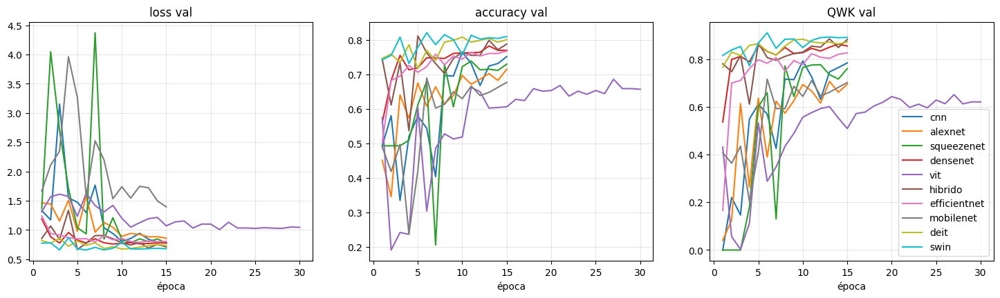

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for k, h in historias.items():
    ax[0].plot(h.ep, h.val_loss, label=k)
    ax[1].plot(h.ep, h.val_accuracy, label=k)
    ax[2].plot(h.ep, h.val_qwk, label=k)
for a, t in zip(ax, ["loss val", "accuracy val", "QWK val"]):
    a.set_title(t); a.set_xlabel("época"); a.grid(alpha=0.3)
ax[2].legend(); plt.show()

## 24. Evaluación en test

Las tablas van ordenadas por QWK. El tiempo de entrenamiento (`train_min`) queda en `resultados.csv`, pero no se muestra: solo se registró para los modelos de la última ronda (Swin, binario, regresión y etapa 2); el de los demás se perdió al recargar los pesos, así que la columna salía casi vacía.

In [30]:
def ms_por_imagen(model, reps=20):
    x = tf.random.normal((CFG["bs"], CFG["img"], CFG["img"], 3))
    for _ in range(3): model.predict_on_batch(x)
    t0 = time.time()
    for _ in range(reps): model.predict_on_batch(x)
    return (time.time() - t0) / (reps * CFG["bs"]) * 1000

y_test = y[te]
filas, preds_test = [], {}
for k, m in modelos.items():
    p = m.predict(ds_test, verbose=0).argmax(1)
    preds_test[k] = p
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average="macro", zero_division=0)
    filas.append(dict(modelo=k, accuracy=accuracy_score(y_test, p), precision=pr, recall=rc, f1=f1,
                      qwk=cohen_kappa_score(y_test, p, weights="quadratic"), params_M=m.count_params() / 1e6,
                      train_min=tiempos[k] / 60, ms_img=ms_por_imagen(m)))
res = pd.DataFrame(filas).set_index("modelo").round(3)
res.to_csv(f"{OUT}/resultados.csv")
def tabla(df):
    cols = [c for c in df.columns if c != "train_min"]
    return df[cols].sort_values("qwk", ascending=False).style.background_gradient(cmap="Greens", subset=["accuracy", "precision", "recall", "f1", "qwk"]).format(precision=3)

tabla(res)

,accuracy,precision,recall,f1,qwk,params_M,ms_img
modelo,,,,,,,
swin,0.793,0.650,0.669,0.650,0.906,27.523,3.606
hibrido,0.787,0.633,0.644,0.629,0.886,5.687,1.992
deit,0.795,0.629,0.617,0.618,0.870,21.668,3.286
efficientnet,0.798,0.672,0.589,0.615,0.859,4.056,0.825
densenet,0.760,0.582,0.610,0.589,0.842,7.043,1.992
squeezenet,0.745,0.582,0.595,0.586,0.820,0.735,0.391
cnn,0.769,0.656,0.505,0.513,0.795,1.176,1.034
alexnet,0.720,0.441,0.473,0.453,0.744,58.306,0.337
mobilenet,0.724,0.452,0.481,0.424,0.723,2.264,0.687


### Evaluación del flujo de dos etapas

1. El autoencoder decide sano / enfermo con la medida y el umbral elegidos en validación.
2. A los que salen "enfermo", el clasificador de severidad les pone un nivel de 1 a 4.

También calculamos el caso **"etapa 1 perfecta"** (como si supiéramos de verdad quién está enfermo), para separar cuánto error viene de cada etapa.


Medida del autoencoder: top 1% (elegida en val)
Etapa 1 (autoencoder) en test: AUC 0.548 | sensibilidad 0.380 | especificidad 0.753
Etapa 2 sola (en los enfermos reales): accuracy 0.631 | QWK 0.568


,accuracy,precision,recall,f1,qwk,params_M,ms_img
modelo,,,,,,,
swin,0.793,0.650,0.669,0.650,0.906,27.523,3.606
dos_etapas (etapa 1 perfecta),0.813,0.653,0.655,0.647,0.890,7.566,nan
hibrido,0.787,0.633,0.644,0.629,0.886,5.687,1.992
deit,0.795,0.629,0.617,0.618,0.870,21.668,3.286
efficientnet,0.798,0.672,0.589,0.615,0.859,4.056,0.825
densenet,0.760,0.582,0.610,0.589,0.842,7.043,1.992
squeezenet,0.745,0.582,0.595,0.586,0.820,0.735,0.391
cnn,0.769,0.656,0.505,0.513,0.795,1.176,1.034
alexnet,0.720,0.441,0.473,0.453,0.744,58.306,0.337


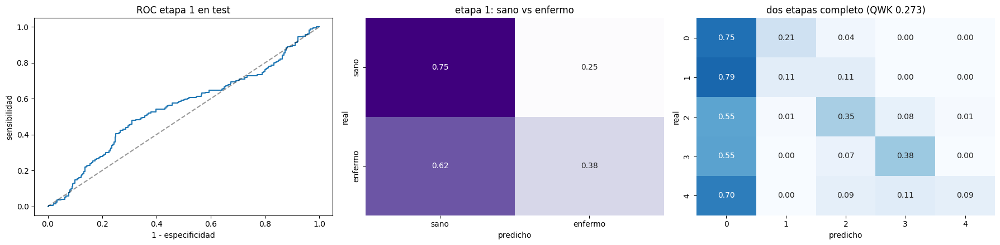

In [31]:
err_te = error_reconstruccion(te)
enfermo = err_te > UMBRAL
sev_te = etapa2["modelo"].predict(ds_test, verbose=0).argmax(1) + 1
pred_2e = np.where(enfermo, sev_te, 0)
pred_oraculo = np.where(y_test > 0, sev_te, 0)

real_enf = y_test > 0
sens, espec = (enfermo & real_enf).sum() / real_enf.sum(), (~enfermo & ~real_enf).sum() / (~real_enf).sum()
print(f"Medida del autoencoder: {MODO} (elegida en val)")
print(f"Etapa 1 (autoencoder) en test: AUC {roc_auc_score(real_enf, err_te):.3f} | sensibilidad {sens:.3f} | especificidad {espec:.3f}")
s_enf = real_enf
print(f"Etapa 2 sola (en los enfermos reales): accuracy {accuracy_score(y_test[s_enf], sev_te[s_enf]):.3f} | "
      f"QWK {cohen_kappa_score(y_test[s_enf], sev_te[s_enf], weights='quadratic'):.3f}")

def fila(nombre, p, params, t_min):
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average="macro", zero_division=0)
    return dict(modelo=nombre, accuracy=accuracy_score(y_test, p), precision=pr, recall=rc, f1=f1,
                qwk=cohen_kappa_score(y_test, p, weights="quadratic"), params_M=params, train_min=t_min, ms_img=np.nan)

params_2e = (ae.count_params() + etapa2["modelo"].count_params()) / 1e6
t_2e = (float(hist_ae["tiempo"].iloc[0]) + etapa2["t"]) / 60
extra = pd.DataFrame([fila("dos_etapas", pred_2e, params_2e, t_2e),
                      fila("dos_etapas (etapa 1 perfecta)", pred_oraculo, params_2e, t_2e)]).set_index("modelo").round(3)
res = pd.concat([res.drop(extra.index, errors="ignore"), extra])
preds_test["dos_etapas"] = pred_2e
res.to_csv(f"{OUT}/resultados.csv")
display(tabla(res))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
fpr_t, tpr_t, _ = roc_curve(real_enf, err_te)
ax[0].plot(fpr_t, tpr_t); ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_title("ROC etapa 1 en test"); ax[0].set_xlabel("1 - especificidad"); ax[0].set_ylabel("sensibilidad")
sns.heatmap(confusion_matrix(real_enf, enfermo, normalize="true"), annot=True, fmt=".2f", cmap="Purples", cbar=False,
            xticklabels=["sano", "enfermo"], yticklabels=["sano", "enfermo"], ax=ax[1])
ax[1].set_title("etapa 1: sano vs enfermo"); ax[1].set_xlabel("predicho"); ax[1].set_ylabel("real")
sns.heatmap(confusion_matrix(y_test, pred_2e, labels=range(5), normalize="true"), annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1, cbar=False, ax=ax[2])
ax[2].set_title(f"dos etapas completo (QWK {res.loc['dos_etapas', 'qwk']:.3f})"); ax[2].set_xlabel("predicho"); ax[2].set_ylabel("real")
plt.tight_layout(); plt.show()

### Evaluación de las mejoras: etapa 1 binaria y regresión

Se agregan a la tabla `res` tres filas nuevas, todas medidas en el mismo test de 550 fotos:
- `dos_etapas_binario`: el flujo de dos etapas con el clasificador binario como puerta y el umbral elegido en val.
- `regresion (cortes fijos)` y `regresion (cortes optimizados)`: la EfficientNetB0 de regresión con los cortes 0.5/1.5/2.5/3.5 y con los cortes optimizados en val.

Esta celda no necesita el autoencoder; si está, también se compara su ROC con la del binario.

Etapa 1 binaria en test: AUC 0.998 | sensibilidad 0.957 | especificidad 0.982


,accuracy,precision,recall,f1,qwk,params_M,ms_img
modelo,,,,,,,
swin,0.793,0.650,0.669,0.650,0.906,27.523,3.606
dos_etapas (etapa 1 perfecta),0.813,0.653,0.655,0.647,0.890,7.566,nan
hibrido,0.787,0.633,0.644,0.629,0.886,5.687,1.992
regresion (cortes optimizados),0.745,0.553,0.533,0.511,0.883,4.051,0.834
regresion (cortes fijos),0.747,0.585,0.580,0.564,0.880,4.051,0.834
dos_etapas_binario,0.785,0.622,0.621,0.614,0.870,11.094,nan
deit,0.795,0.629,0.617,0.618,0.870,21.668,3.286
efficientnet,0.798,0.672,0.589,0.615,0.859,4.056,0.825
densenet,0.760,0.582,0.610,0.589,0.842,7.043,1.992


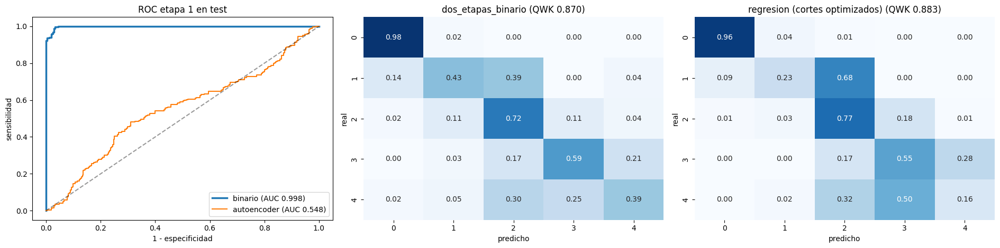

In [32]:
def fila_test(nombre, p, params, t_seg, ms=np.nan):
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average="macro", zero_division=0)
    return dict(modelo=nombre, accuracy=accuracy_score(y_test, p), precision=pr, recall=rc, f1=f1,
                qwk=cohen_kappa_score(y_test, p, weights="quadratic"), params_M=params, train_min=t_seg / 60, ms_img=ms)

y_test = y[te]
nuevas = []

if "etapa1_bin" in globals():
    p_bin_te = prob_enfermo(te)
    enf_bin_te = p_bin_te > UMBRAL_BIN
    sev_te = severidad(te)
    pred_2b = np.where(enf_bin_te, sev_te, 0)
    real_enf = y_test > 0
    sens_b = (enf_bin_te & real_enf).sum() / real_enf.sum()
    espec_b = (~enf_bin_te & ~real_enf).sum() / (~real_enf).sum()
    print(f"Etapa 1 binaria en test: AUC {roc_auc_score(real_enf, p_bin_te):.3f} | sensibilidad {sens_b:.3f} | especificidad {espec_b:.3f}")
    params_2b = (etapa1_bin["modelo"].count_params() + etapa2["modelo"].count_params()) / 1e6
    nuevas.append(fila_test("dos_etapas_binario", pred_2b, params_2b, etapa1_bin["t"] + etapa2["t"]))
    preds_test["dos_etapas_binario"] = pred_2b

if "reg" in globals():
    pred_reg_te = reg["modelo"].predict(ds_test, verbose=0).ravel()
    p_rf, p_ro = a_clase(pred_reg_te), a_clase(pred_reg_te, CORTES)
    params_r, ms_r = reg["modelo"].count_params() / 1e6, ms_por_imagen(reg["modelo"])
    nuevas += [fila_test("regresion (cortes fijos)", p_rf, params_r, reg["t"], ms_r),
               fila_test("regresion (cortes optimizados)", p_ro, params_r, reg["t"], ms_r)]
    preds_test["regresion (cortes optimizados)"] = p_ro

extra = pd.DataFrame(nuevas).set_index("modelo").round(3)
res = pd.concat([res.drop(extra.index, errors="ignore"), extra])
res.to_csv(f"{OUT}/resultados.csv")
display(tabla(res))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
if "etapa1_bin" in globals():
    f_, t_, _ = roc_curve(real_enf, p_bin_te)
    ax[0].plot(f_, t_, lw=2.5, label=f"binario (AUC {roc_auc_score(real_enf, p_bin_te):.3f})")
    if "err_te" in globals():
        f_, t_, _ = roc_curve(real_enf, err_te)
        ax[0].plot(f_, t_, label=f"autoencoder (AUC {roc_auc_score(real_enf, err_te):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4); ax[0].legend()
    ax[0].set_title("ROC etapa 1 en test"); ax[0].set_xlabel("1 - especificidad"); ax[0].set_ylabel("sensibilidad")
for a, k in zip(ax[1:], ["dos_etapas_binario", "regresion (cortes optimizados)"]):
    if k in preds_test:
        sns.heatmap(confusion_matrix(y_test, preds_test[k], labels=range(5), normalize="true"), annot=True, fmt=".2f",
                    cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a)
        a.set_title(f"{k} (QWK {res.loc[k, 'qwk']:.3f})"); a.set_xlabel("predicho"); a.set_ylabel("real")
    else:
        a.axis("off")
plt.tight_layout(); plt.show()

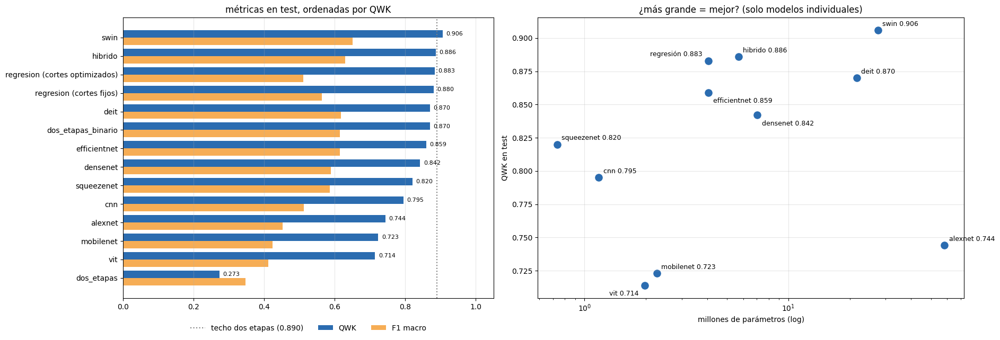

In [33]:
TECHO = "dos_etapas (etapa 1 perfecta)"
r = res.drop(index=TECHO, errors="ignore").sort_values("qwk")
fig, ax = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw=dict(width_ratios=[1, 1.15]))
pos = np.arange(len(r))
ax[0].barh(pos + 0.2, r.qwk, 0.4, label="QWK", color="#2b6cb0")
ax[0].barh(pos - 0.2, r.f1, 0.4, label="F1 macro", color="#f6ad55")
for p_, q in zip(pos, r.qwk):
    ax[0].text(q + 0.01, p_ + 0.2, f"{q:.3f}", va="center", fontsize=8)
if TECHO in res.index:
    ax[0].axvline(res.loc[TECHO, "qwk"], color="gray", ls=":", label=f"techo dos etapas ({res.loc[TECHO, 'qwk']:.3f})")
ax[0].set_yticks(pos, r.index); ax[0].set_xlim(0, 1.05)
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, frameon=False)
ax[0].set_title("métricas en test, ordenadas por QWK"); ax[0].grid(axis="x", alpha=0.3)

s = r[r.ms_img.notna()].drop(index="regresion (cortes fijos)", errors="ignore")
s = s.rename(index={"regresion (cortes optimizados)": "regresión"})
off = {"regresión": (-8, 6), "efficientnet": (6, -14), "hibrido": (6, 6), "densenet": (6, -14), "vit": (-8, -14), "mobilenet": (6, 6)}
ax[1].scatter(s.params_M, s.qwk, s=90, color="#2b6cb0")
for k, row in s.iterrows():
    dx, dy = off.get(k, (6, 6))
    ax[1].annotate(f"{k} {row.qwk:.3f}", (row.params_M, row.qwk), xytext=(dx, dy), textcoords="offset points",
                   fontsize=9, ha="right" if dx < 0 else "left")
ax[1].set_xscale("log"); ax[1].set_xlabel("millones de parámetros (log)"); ax[1].set_ylabel("QWK en test")
ax[1].set_title("¿más grande = mejor? (solo modelos individuales)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 25. Heatmap #1: matrices de confusión

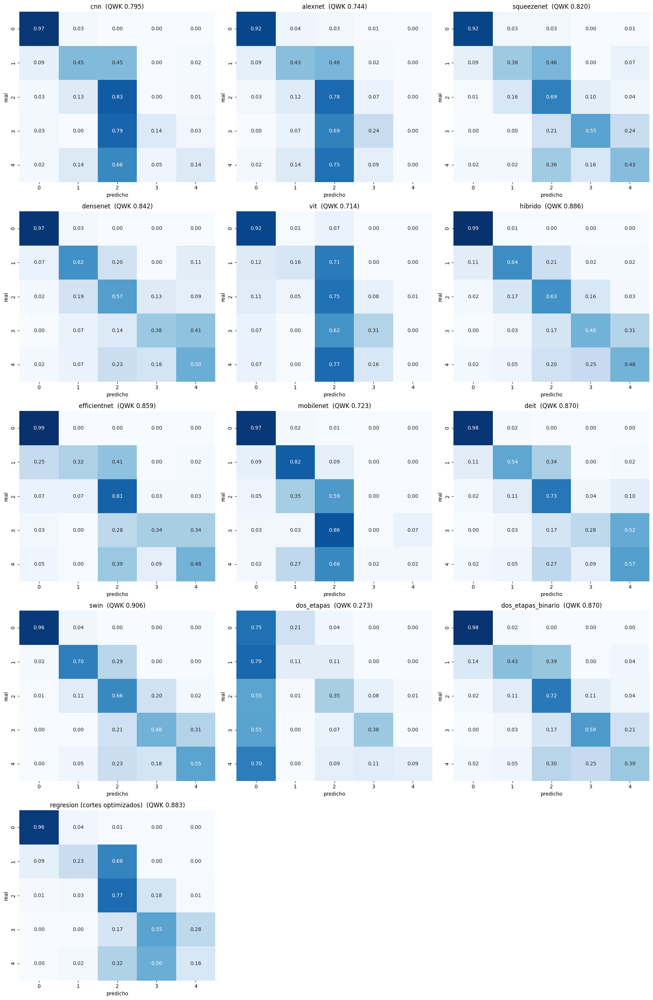

In [34]:
n_cm = len(preds_test)
filas_cm = int(np.ceil(n_cm / 3))
fig, ax = plt.subplots(filas_cm, 3, figsize=(18, 5.5 * filas_cm), squeeze=False)
for a in ax.ravel()[n_cm:]: a.axis("off")
for a, (k, p) in zip(ax.ravel(), preds_test.items()):
    cm = confusion_matrix(y_test, p, labels=range(5), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a)
    a.set_title(f"{k}  (QWK {res.loc[k, 'qwk']:.3f})"); a.set_xlabel("predicho"); a.set_ylabel("real")
plt.tight_layout(); plt.show()

## 26. Heatmaps #2: familia CAM, hecha a mano

Todos salen de lo mismo: las activaciones `A` de la capa elegida y los gradientes `G` de la clase predicha respecto a esas activaciones. Lo que cambia es cómo se combinan.

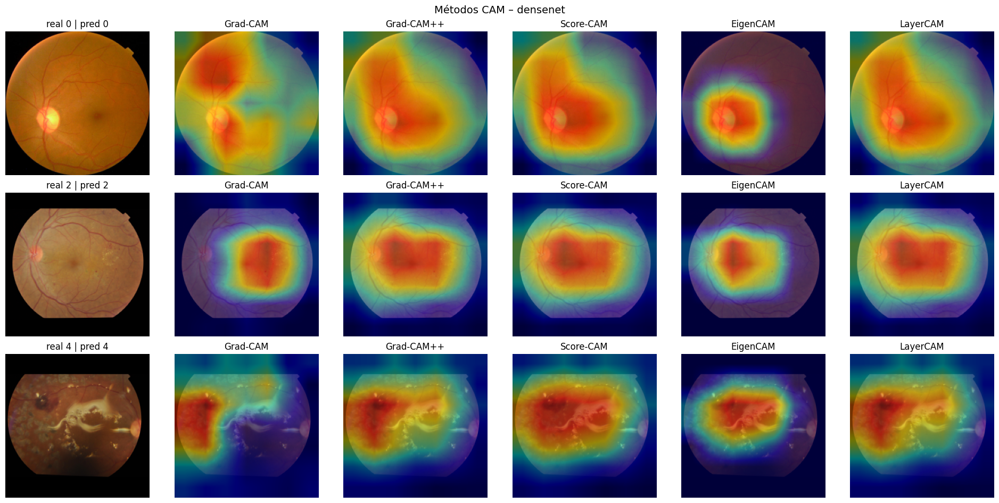

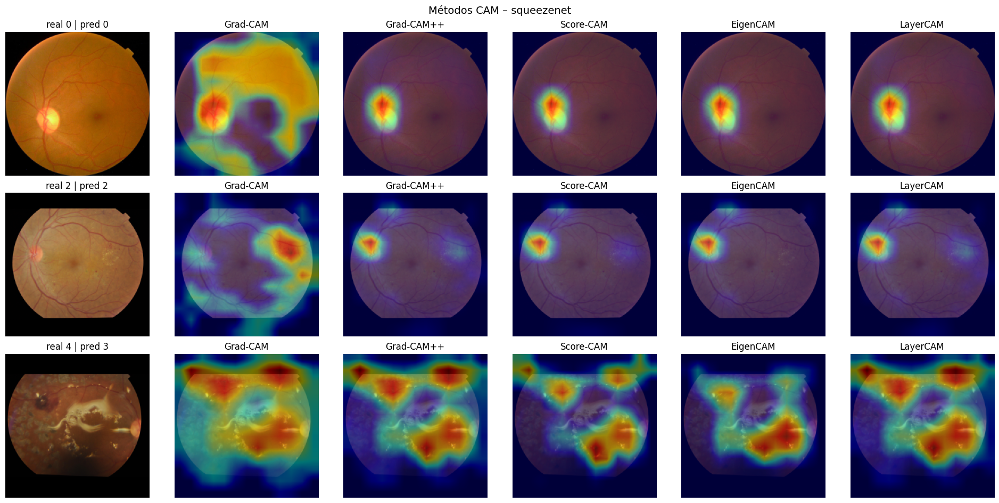

In [35]:
def norm01(m):
    m = np.maximum(m, 0)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

def entrada(ids):
    return normalizar(Xb[ids])

def overlay(j, mapa, alpha=0.45):
    mapa = cv2.resize(norm01(mapa), (CFG["img"], CFG["img"]))
    color = cv2.applyColorMap(np.uint8(255 * mapa), cv2.COLORMAP_JET)[..., ::-1]
    return np.uint8(X[j] * (1 - alpha) + color * alpha)

def act_y_grad(k, x, clases):
    gm = keras.Model(modelos[k].inputs, [modelos[k].get_layer(capas[k]).output, modelos[k].output])
    with tf.GradientTape() as tape:
        A, out = gm(x, training=False)
        sc = tf.gather(tf.cast(out, tf.float32), clases, axis=1, batch_dims=1)
    G = tape.gradient(sc, A)
    return tf.cast(A, tf.float32).numpy(), tf.cast(G, tf.float32).numpy()

def gradcam(A, G):
    return (G.mean((1, 2), keepdims=True) * A).sum(-1)

def gradcam_pp(A, G):
    g2, g3 = G ** 2, G ** 3
    alpha = g2 / (2 * g2 + A.sum((1, 2), keepdims=True) * g3 + 1e-7)
    alpha = np.where(G != 0, alpha, 0)
    w = (alpha * np.maximum(G, 0)).sum((1, 2), keepdims=True)
    return (w * A).sum(-1)

def layercam(A, G):
    return (np.maximum(G, 0) * A).sum(-1)

def eigencam(A, G=None):
    out = []
    for a in A:
        h, w_, c = a.shape
        M = a.reshape(-1, c)
        M = M - M.mean(0)
        _, _, vt = np.linalg.svd(M, full_matrices=False)
        p = (M @ vt[0]).reshape(h, w_)
        out.append(p if np.corrcoef(p.ravel(), a.mean(-1).ravel())[0, 1] >= 0 else -p)
    return np.stack(out)

def scorecam(k, x, clases, lote=32):
    gm = keras.Model(modelos[k].inputs, modelos[k].get_layer(capas[k]).output)
    A = tf.cast(gm(x, training=False), tf.float32)
    out = []
    for i in range(len(x)):
        M = tf.transpose(tf.image.resize(A[i:i + 1], x.shape[1:3])[0], (2, 0, 1))
        mn, mx = tf.reduce_min(M, (1, 2), keepdims=True), tf.reduce_max(M, (1, 2), keepdims=True)
        M = (M - mn) / (mx - mn + 1e-8)
        sc = []
        for s in range(0, M.shape[0], lote):
            xm = x[i][None] * M[s:s + lote, ..., None]
            sc.append(tf.nn.softmax(tf.cast(modelos[k](xm, training=False), tf.float32))[:, clases[i]])
        w = tf.nn.softmax(tf.concat(sc, 0)).numpy()
        out.append((A[i].numpy() * w).sum(-1))
    return np.stack(out)

METODOS = ["Grad-CAM", "Grad-CAM++", "Score-CAM", "EigenCAM", "LayerCAM"]

def calcular_cam(k, ids, metodo, clases=None):
    x = entrada(ids)
    if clases is None:
        clases = modelos[k].predict(x, verbose=0).argmax(1)
    clases = np.asarray(clases)
    if metodo == "Score-CAM":
        return scorecam(k, x, clases), clases
    A, G = act_y_grad(k, x, clases)
    f = dict(zip(["Grad-CAM", "Grad-CAM++", "EigenCAM", "LayerCAM"], [gradcam, gradcam_pp, eigencam, layercam]))[metodo]
    return f(A, G), clases

def comparar_metodos(k, ids):
    fig, ax = plt.subplots(len(ids), len(METODOS) + 1, figsize=(3.2 * (len(METODOS) + 1), 3.2 * len(ids)), squeeze=False)
    for c, met in enumerate(METODOS, 1):
        g, pred = calcular_cam(k, ids, met)
        for r, j in enumerate(ids):
            ax[r, c].imshow(overlay(j, g[r])); ax[r, c].set_title(met)
    for r, j in enumerate(ids):
        ax[r, 0].imshow(X[j]); ax[r, 0].set_title(f"real {y[j]} | pred {pred[r]}")
    for a in ax.ravel(): a.axis("off")
    plt.suptitle(f"Métodos CAM – {k}", fontsize=14); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
ejemplos = [int(rng.choice(te[y[te] == c])) for c in [0, 2, 4]]

for k in ["densenet", "squeezenet"]:
    comparar_metodos(k, ejemplos)

## 27. Heatmaps #3: mismo ojo, distintos modelos (Grad-CAM)

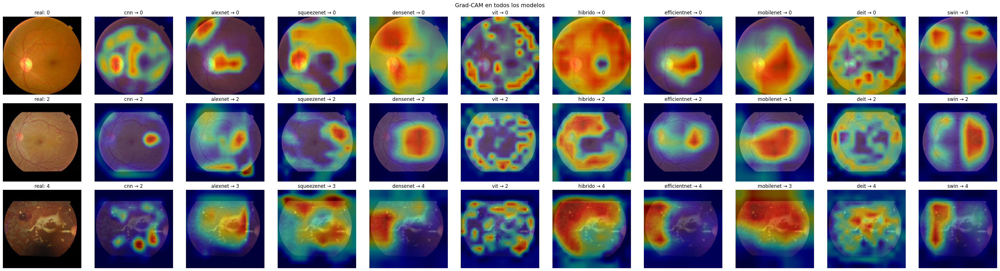

In [36]:
def comparar_modelos(ids, metodo="Grad-CAM"):
    fig, ax = plt.subplots(len(ids), len(modelos) + 1, figsize=(3.2 * (len(modelos) + 1), 3.2 * len(ids)), squeeze=False)
    for c, k in enumerate(modelos, 1):
        g, pred = calcular_cam(k, ids, metodo)
        for r, j in enumerate(ids):
            ax[r, c].imshow(overlay(j, g[r])); ax[r, c].set_title(f"{k} → {pred[r]}")
    for r, j in enumerate(ids):
        ax[r, 0].imshow(X[j]); ax[r, 0].set_title(f"real: {y[j]}")
    for a in ax.ravel(): a.axis("off")
    plt.suptitle(f"{metodo} en todos los modelos", fontsize=14); plt.tight_layout(); plt.show()

comparar_modelos(ejemplos)

## 28. Heatmaps #4: Integrated Gradients (pixel a pixel)

Vamos de una imagen negra (baseline) a la imagen real en `pasos` pasos, acumulamos los gradientes en el camino y los multiplicamos por la diferencia con el baseline.

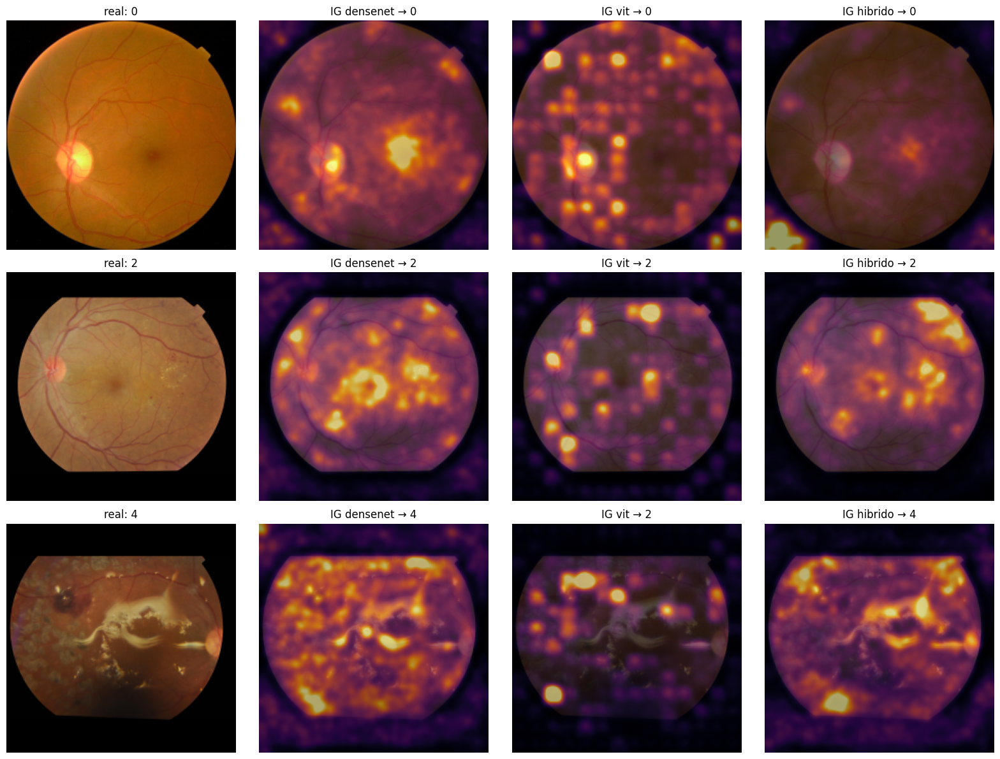

In [37]:
def integrated_gradients(k, ids, pasos=32, lote=16):
    x = entrada(ids)
    clases = modelos[k].predict(x, verbose=0).argmax(1)
    base = normalizar(np.zeros((1, CFG["img"], CFG["img"], 3)))
    alphas = tf.reshape(tf.linspace(0.0, 1.0, pasos + 1), (-1, 1, 1, 1))
    out = []
    for i in range(len(ids)):
        camino = base + alphas * (x[i:i + 1] - base)
        grads = []
        for s in range(0, pasos + 1, lote):
            b = camino[s:s + lote]
            with tf.GradientTape() as t:
                t.watch(b)
                sc = tf.cast(modelos[k](b, training=False), tf.float32)[:, clases[i]]
            grads.append(t.gradient(sc, b))
        g = tf.concat(grads, 0)
        ig = (x[i] - base[0]) * tf.reduce_mean((g[:-1] + g[1:]) / 2, 0)
        a = cv2.GaussianBlur(np.abs(ig.numpy()).sum(-1), (0, 0), 3)
        out.append(np.clip(a / (np.percentile(a, 99) + 1e-8), 0, 1))
    return np.stack(out), clases

comparar = ["densenet", "vit", "hibrido"]
fig, ax = plt.subplots(len(ejemplos), len(comparar) + 1, figsize=(4 * (len(comparar) + 1), 4 * len(ejemplos)), squeeze=False)
for c, k in enumerate(comparar, 1):
    a, pred = integrated_gradients(k, ejemplos)
    for r, j in enumerate(ejemplos):
        ax[r, c].imshow(X[j]); ax[r, c].imshow(a[r], cmap="inferno", alpha=0.6); ax[r, c].set_title(f"IG {k} → {pred[r]}")
for r, j in enumerate(ejemplos):
    ax[r, 0].imshow(X[j]); ax[r, 0].set_title(f"real: {y[j]}")
for a_ in ax.ravel(): a_.axis("off")
plt.tight_layout(); plt.show()

## 29. Heatmaps #5: Attention Rollout (ViT e híbrido)

Aquí no usamos gradientes, sino las matrices de atención de todas las capas del transformer multiplicadas entre sí (Abnar & Zuidema, 2020). Como no usamos token CLS, al final promediamos cuánta atención recibe cada parche.

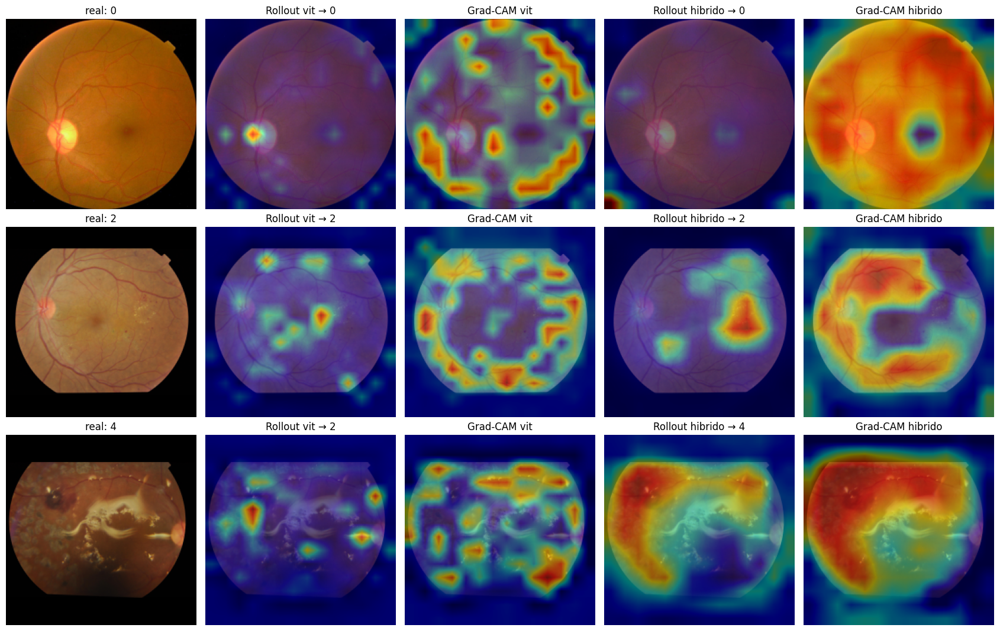

In [38]:
def attention_rollout(k, ids):
    atts = modelos[k].atencion(entrada(ids), training=False)
    atts = [tf.cast(a, tf.float32).numpy() for a in (atts if isinstance(atts, (list, tuple)) else [atts])]
    n = atts[0].shape[-1]
    R = np.repeat(np.eye(n)[None], len(ids), 0)
    for a in atts:
        a = a.mean(1) + np.eye(n)
        R = (a / a.sum(-1, keepdims=True)) @ R
    lado = int(n ** 0.5)
    return R.mean(1).reshape(-1, lado, lado)

fig, ax = plt.subplots(len(ejemplos), 5, figsize=(17, 3.6 * len(ejemplos)), squeeze=False)
for c, k in enumerate(["vit", "hibrido"]):
    roll = attention_rollout(k, ejemplos)
    gcam, pred = calcular_cam(k, ejemplos, "Grad-CAM")
    for r, j in enumerate(ejemplos):
        ax[r, 1 + 2 * c].imshow(overlay(j, roll[r])); ax[r, 1 + 2 * c].set_title(f"Rollout {k} → {pred[r]}")
        ax[r, 2 + 2 * c].imshow(overlay(j, gcam[r])); ax[r, 2 + 2 * c].set_title(f"Grad-CAM {k}")
for r, j in enumerate(ejemplos):
    ax[r, 0].imshow(X[j]); ax[r, 0].set_title(f"real: {y[j]}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 30. Heatmaps #6: error de reconstrucción del autoencoder

Otro tipo de mapa de calor, que sale gratis del autoencoder: dónde la reconstrucción se parece menos a la imagen real. En un ojo enfermo esperamos que las zonas rojas caigan sobre las lesiones, porque el autoencoder solo aprendió a reconstruir retinas sanas.

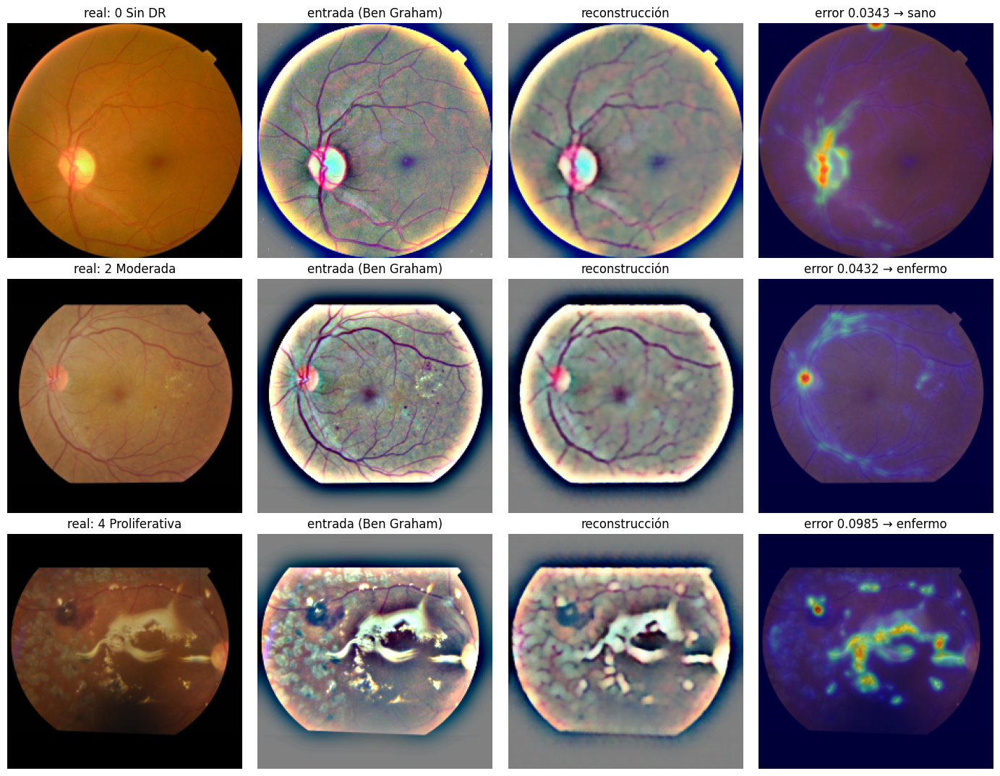

In [39]:
mapa_err = error_reconstruccion(np.array(ejemplos), por_pixel=True)
recon = ae.predict(Xb[ejemplos].astype(np.float32) / 255.0, verbose=0)
err_ej = error_reconstruccion(np.array(ejemplos))

fig, ax = plt.subplots(len(ejemplos), 4, figsize=(14, 3.6 * len(ejemplos)), squeeze=False)
for r, j in enumerate(ejemplos):
    ax[r, 0].imshow(X[j]); ax[r, 0].set_title(f"real: {CLASES[y[j]]}")
    ax[r, 1].imshow(Xb[j]); ax[r, 1].set_title("entrada (Ben Graham)")
    ax[r, 2].imshow(np.clip(recon[r], 0, 1)); ax[r, 2].set_title("reconstrucción")
    ax[r, 3].imshow(overlay(j, cv2.GaussianBlur(mapa_err[r], (0, 0), 3)))
    ax[r, 3].set_title(f"error {err_ej[r]:.4f} → {'enfermo' if err_ej[r] > UMBRAL else 'sano'}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 31. ¿Dónde mira cuando se equivoca?

mejor modelo (por QWK en val): swin | errores en test: 114 de 550


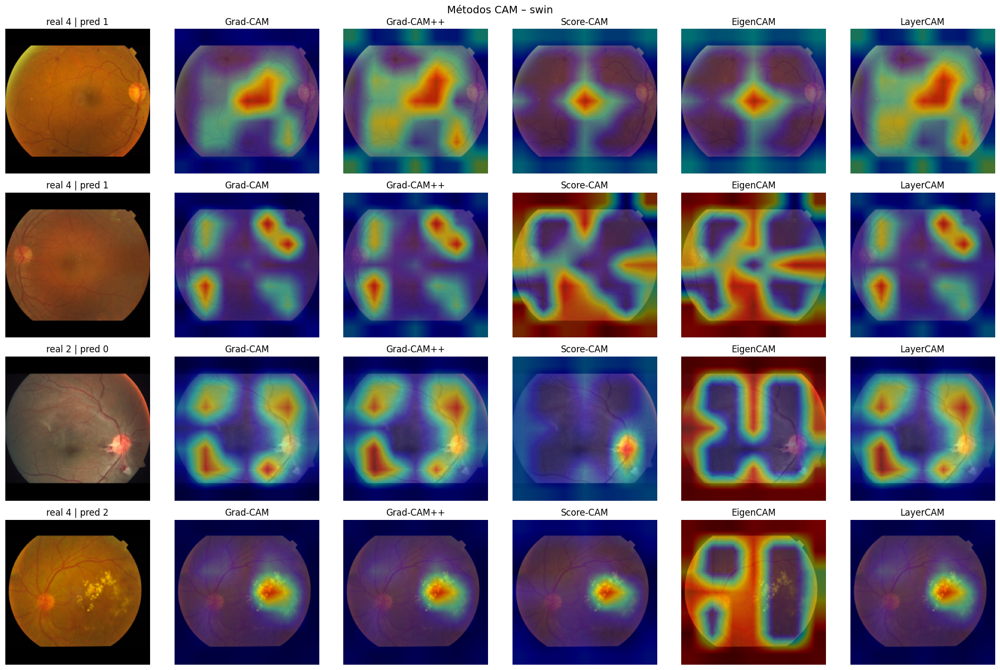

In [40]:
mejor = max(historias, key=lambda k: historias[k].val_qwk.max())
p = preds_test[mejor]
mal = p != y_test
errores = te[mal][np.argsort(-np.abs(p[mal] - y_test[mal]))][:4]
print(f"mejor modelo (por QWK en val): {mejor} | errores en test: {mal.sum()} de {len(te)}")
comparar_metodos(mejor, list(errores))

## 32. Conclusiones

**Resultados finales en test (550 imágenes que ningún modelo vio al entrenar)**

| Modelo | Tipo | Params (M) | Accuracy | F1 macro | QWK | ms/img |
|---|---|---|---|---|---|---|
| **Swin-Tiny** | transformer preentrenado | 27.5 | 0.793 | **0.650** | **0.906** | 4.26 |
| Híbrido DenseNet + Transformer | CNN preentrenada + transformer | 5.7 | 0.787 | 0.629 | 0.886 | 2.16 |
| Regresión EfficientNetB0 (cortes optimizados) | CNN preentrenada, 1 salida | 4.1 | 0.745 | 0.511 | 0.883 | 0.91 |
| Regresión EfficientNetB0 (cortes fijos) | CNN preentrenada, 1 salida | 4.1 | 0.747 | 0.564 | 0.880 | 0.91 |
| Dos etapas: binario + DenseNet | EfficientNetB0 + DenseNet121 | 11.1 | 0.785 | 0.614 | 0.870 | – |
| DeiT-Small | transformer preentrenado | 21.7 | 0.795 | 0.618 | 0.870 | 3.63 |
| EfficientNetB0 | CNN preentrenada | 4.1 | **0.798** | 0.615 | 0.859 | 0.90 |
| DenseNet121 | CNN preentrenada | 7.0 | 0.760 | 0.589 | 0.842 | 2.11 |
| SqueezeNet 1.1 + BN | CNN desde cero | 0.7 | 0.745 | 0.586 | 0.820 | **0.35** |
| CNN simple | CNN desde cero | 1.2 | 0.769 | 0.513 | 0.795 | 1.08 |
| AlexNet + BN | CNN desde cero | 58.3 | 0.720 | 0.453 | 0.744 | 0.38 |
| MobileNetV2 | CNN preentrenada | 2.3 | 0.724 | 0.424 | 0.723 | 0.76 |
| ViT | transformer desde cero | 2.0 | 0.689 | 0.412 | 0.714 | 0.56 |
| Dos etapas: autoencoder + DenseNet | detección de anomalías | 7.6 | 0.504 | 0.347 | 0.273 | – |
| *Dos etapas con etapa 1 perfecta (referencia, no es un modelo)* | | 7.6 | 0.813 | 0.647 | 0.890 | – |

**¿Quién ganó?**
- **Swin-Tiny** es el mejor en QWK (0.906), F1 macro (0.650) y recall macro (0.669), y es el que mejor acierta la clase 1 (70%). Pero la diferencia con el híbrido (0.886) es de 0.02, y entre corridas los resultados se mueven hasta 0.03, así que lo honesto es hablar de un **grupo de cabeza** entre 0.87 y 0.91: Swin, híbrido, regresión, DeiT y el flujo de dos etapas con binario.
- El precio de Swin es el tamaño: 27.5 M de parámetros y 4.3 ms por imagen. El híbrido logra 0.886 con 5.7 M, y la regresión 0.88 con 4.1 M y menos de 1 ms.

**Preentrenar es lo que más pesa**
- Los dos transformers preentrenados (Swin 0.906 y DeiT 0.870) le sacan casi 0.2 de QWK al ViT desde cero (0.714). Con 2.563 imágenes de train un transformer no alcanza a aprender solo lo que una CNN trae por diseño (localidad, invariancia a traslación).
- Más parámetros no es mejor: SqueezeNet (0.7 M, desde cero) saca 0.820 y AlexNet (58 M) 0.744.

**Ojo con el QWK solo**
- La CNN simple y AlexNet tienen QWK aceptable pero mandan casi todos los enfermos a la clase 2 (ver matrices). El QWK las premia porque se equivocan "cerca"; el F1 macro (0.51 y 0.45) muestra que casi no distinguen niveles. Por eso reportamos los dos.
- La clase 0 la aciertan todos (92–99%). Las confusiones fuertes son 1↔2 y 3↔4, y la clase 3 es la más difícil (solo ~29 imágenes en test, así que su porcentaje se mueve mucho con pocos errores).

### Qué aprendimos de cada experimento

**Flujo de dos etapas**
- Con el **autoencoder** como etapa 1 el flujo no sirvió: AUC de 0.548 en test (casi azar) y QWK de 0.273, porque solo detectaba al 38% de los enfermos. En ojos sanos el disco óptico y los vasos también se reconstruyen mal, así que el error de reconstrucción no separa las clases. Probamos 4 formas de medir el error y ninguna pasó de 0.52 de AUC en validación.
- Con el **clasificador binario** (EfficientNetB0) la etapa 1 pasa a AUC 0.998, sensibilidad 0.957 y especificidad 0.982 en test, y el flujo sube de **0.273 a 0.870**, muy cerca de su techo de 0.890. La diferencia que queda viene de la etapa 2 (QWK 0.568 entre los enfermos).
- Aun así, el flujo no le gana al mejor modelo único: usa dos redes (11.1 M) para quedar al nivel de DeiT. Su valor está en que la decisión sano / enfermo es muy confiable por sí sola, que es justo lo que se usaría en un tamizaje.

**Regresión con cortes optimizados**
- Predecir la severidad como un número sube la misma EfficientNetB0 de **0.859 a 0.880** de QWK con los cortes fijos (0.5, 1.5, 2.5, 3.5), porque el modelo aprende desde el entrenamiento que la escala tiene orden.
- Optimizar los cortes subió el QWK en validación de 0.846 a 0.875, pero en test solo de 0.880 a 0.883, y el F1 macro **bajó** de 0.564 a 0.511. Los cortes se acomodaron a la validación (sobreajuste) y el corte de la clase 4 quedó tan alto (3.65) que solo acierta el 16% de los ojos de clase 4. La regresión además "comprime" los extremos: los ojos de clase 4 salen con un valor típico de 2.5.
- Conclusión: la regresión sí ayuda; la optimización de cortes, con una sola partición de validación, casi no.

**Swin-Tiny**
- Quedó primero. Necesitó actualizar `keras-hub` a la 0.33 (la versión que traía Colab no lo incluía).
- Sus mapas de calor son más gruesos (la última etapa es de 7×7) y en el ojo sano marca zonas pegadas al borde de la foto, lo que refuerza la sospecha de que algunos modelos usan el borde de la foto como pista.

### Mapas de calor
- En DenseNet121 los cinco métodos CAM coinciden bastante, y en el ojo de clase 4 cubren la zona de la lesión. EigenCAM sale más centrado porque no depende de la clase.
- Los mejores modelos (DenseNet, EfficientNet, híbrido) miran la zona con exudados y hemorragias. La CNN simple se fija en el **disco óptico**, que es normal: posible atajo.
- ViT y DeiT muestran cuadritos (parches de 16×16) y Swin bloques más grandes (7×7).
- Integrated Gradients es más fino: en los ojos enfermos resalta puntos brillantes (exudados). En el ojo sano, DenseNet marca la mácula y el disco óptico, y el híbrido una mancha fuera de la retina (otra pista del atajo del borde).
- El mapa de error del autoencoder sí cae sobre las lesiones en ojos enfermos, pero también sobre el disco y los vasos en ojos sanos, y por eso no sirve para separar.
- Los errores más grandes del mejor modelo son ojos de clase 4 predichos como 1 o 2, en fotos oscuras o de bajo contraste. Ahí los mapas se riegan o marcan zonas fuera de la retina. En el último caso de la sección 31, Swin marca bien los exudados pero no detecta lo que hace que el ojo sea de clase 4.

## 33. Qué haríamos distinto (si hubiera más tiempo)

- **Ensamble:** promediar Swin, el híbrido y la regresión, como hizo el ganador de APTOS 2019 (8 modelos, QWK 0.936 en su leaderboard privado, que no es comparable con nuestro test).
- **Validación cruzada:** con ~29 imágenes de clase 3 en test, una sola partición da resultados ruidosos; también ayudaría a elegir los cortes de la regresión sin sobreajustarlos.
- **Enmascarar el fondo negro** y volver a mirar los mapas, para confirmar si los modelos usan el borde de la foto como atajo.
- **Imágenes más grandes** (384 o 512): los microaneurismas de la clase 1 son de pocos pixeles a 224×224.
- **Augmentation en GPU:** cada época tarda 30–40 s porque las augmentations corren en los 2 CPUs de Colab y la GPU se queda esperando.
- **Guardar siempre el tiempo de entrenamiento:** al recargar pesos se perdió el registro de los primeros modelos.